# Phase 1: Test on assembly_1

## Section 1 - Purpose and protocol

This notebook measures the Phase 1 perception once, on the test recording assembly_1.

The method is fixed and nothing is chosen here. C-RADIOv4-SO400M is used frozen, with input 1024x1024. Patches are classified by V2, the nearest labelled patch of the support set of 10 frames, with background margin 0. The prototypes are loaded from the file saved by the pipeline at v1.9-pipeline (outputs/phase_1_perception/patch_prototypes.npz).

The 32 validation frames of assembly_2 were used to choose the method and the support set. Their values are therefore optimistic: an estimate made on data used for selection is biased (Cawley and Talbot 2010, Sect. 5). The test frames give the estimate that no choice has seen.

assembly_1 was never used for any choice. It was inspected once, qualitatively, in v1-baseline, before any method was chosen. At that time only f0073 was annotated.

The work follows a fixed order, and each step is committed before the next. First the event log of assembly_1 (configs/assembly_1_events.json). Then the rules and the list of test frames (Section 3). Then the annotation of these frames (Section 4) and the measurement plan (Section 5). Only then the single execution (Sections 6 and 7). No result of this notebook changes the method, the support set or the frames.

assembly_1 follows the same procedure as assembly_2, with the pieces in the same order, the same operator and the same environment. The test therefore measures perception on a new recording of the same procedure. It does not measure a different order, operator or scene.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 1:

Cawley and Talbot 2010, Sect. 5: training and model selection must be treated together and never performed separately at any point of the evaluation; protocols that do not respect this give optimistically biased performance estimates.

Pipeline (phase_1_perception.ipynb), Section 6.4: the V2 prototypes saved with their classes and metadata.

Support-set study on V2, Section 3: the rules used to choose the validation frames, adapted here in Section 3.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 2 - Configuration

All paths, classes, settings and test frames in one place.

The prototypes are not rebuilt: they are loaded from the file saved by the pipeline (Section 6), so this notebook reads no reference frame. The values of MIN_LABEL_COVERAGE and MARGIN written here are those of the pipeline; Section 6 checks them against the metadata saved with the prototypes.

The test frames are listed in 2.6, with the moment and the piece of each one. Section 3 recomputes them from the event log with the rules, and checks that the two lists are equal. This is the only notebook that reads frames of assembly_1 for evaluation, so frame_path accepts only them.

In [1]:
# 2.1 Dependencies: install once per environment with pip install -r requirements.txt (README, Setup)

In [26]:
# 2.2 Imports
import json
import sys
import time
import platform
import hashlib
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
import transformers
import cv2

In [27]:
# 2.3 Paths and shared module
PROJECT_ROOT = Path.cwd().parent
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))   # makes src/perception importable from notebooks/

MODEL_DIR = PROJECT_ROOT / "models" / "c_radio_weights"
FRAMES_DIR = PROJECT_ROOT / "data" / "extracted_frames"
EVENTS_PATH = PROJECT_ROOT / "configs" / "assembly_1_events.json"                       # event log of the test video
VIDEO_PATH = PROJECT_ROOT / "data" / "raw_videos" / "assembly_1.mp4"                      # Section 8, description only
PROTOTYPES_PATH = PROJECT_ROOT / "outputs" / "phase_1_perception" / "patch_prototypes.npz"  # saved by the pipeline, read only
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "phase_1_test"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for name, path in {"MODEL_DIR": MODEL_DIR, "FRAMES_DIR": FRAMES_DIR, "EVENTS_PATH": EVENTS_PATH, "VIDEO_PATH": VIDEO_PATH,
                   "PROTOTYPES_PATH": PROTOTYPES_PATH, "SRC_DIR": SRC_DIR}.items():
    status = "OK" if path.exists() else "MISSING"
    print(f"[{status}] {name}: {path}")

# Shared code (src/perception), used by every Phase 1 notebook
from perception.features import FeatureExtractor
from perception.labels import sequence_of, check_annotation, rasterize_annotation, patch_label_grid
from perception.prototypes import load_patch_prototypes, sort_by_class, class_similarities_gpu, assign_labels
from perception.metrics import (confusion_matrix, frame_iou, frame_miou, bootstrap_miou, bootstrap_class_iou,
                                percentile_interval, MERGED_NAMES)
from perception.visualization import label_grid_to_rgb, render_overlay

[OK] MODEL_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\models\c_radio_weights
[OK] FRAMES_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\data\extracted_frames
[OK] EVENTS_PATH: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\configs\assembly_1_events.json
[OK] VIDEO_PATH: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\data\raw_videos\assembly_1.mp4
[OK] PROTOTYPES_PATH: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\phase_1_perception\patch_prototypes.npz
[OK] SRC_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\src


In [28]:
# 2.4 Official class list, defined once in src/perception/classes.py and shared by all notebooks
from perception.classes import (CLASS_NAMES, BACKGROUND_ID, BACKGROUND_LABEL, IGNORE_ID, HAND_LABEL, PIECE_LABELS,
                                LEGACY_LABELS, CLASS_COLORS)

print(f"{len(CLASS_NAMES)} classes: {CLASS_NAMES}")

12 classes: ['background', 'body', 'base', 'hat', 'eyes', 'ear', 'nose', 'moustache', 'mouth', 'arm_1', 'arm_2', 'hand']


In [29]:
# 2.5 Settings
# Values of the pipeline (phase_1_perception.ipynb, Section 2.5); Section 6 checks them against the saved metadata.

# --- Feature extraction (Section 7) ---
DEVICE = "cuda"
DTYPE = torch.bfloat16

# --- Patch labelling of the ground truth (Section 4) ---
MIN_LABEL_COVERAGE = 0.5        # a patch gets a class label if that class covers at least half of it (pipeline, Section 5)

# --- Uncertainty (Sections 5 and 7), as in validation (support-set study on V2, cell 8.3) ---
N_BOOTSTRAP = 1000              # resamples of the frames
BLOCK = 3                       # consecutive frames per block: a pause, a pick and a mounting of one piece (Section 5)

# --- Classification (Section 7) ---
MARGIN = 0.0                    # background margin of V2 (margin study, Section 9)

# --- Figures (Sections 4 and 7) ---
MIN_BLOB_PATCHES = 5            # smallest blob that gets a text label in the overlays, as in the pipeline

# --- Video (Section 8, description only): values of the pipeline (Section 2.5), provisional, set on assembly_2 ---
MOTION_THRESHOLD = 1.0          # mean absolute grey-level difference (0-255) between consecutive frames
STABLE_FRAMES_NEEDED = 5        # consecutive still frames before running C-RADIO (~167 ms at 30 fps)
MOTION_SIZE = (320, 320)        # frames are downscaled before computing the motion score

# --- Reproducibility ---
RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)
_ = torch.manual_seed(RANDOM_SEED)

In [6]:
# 2.6 Test frames
# Test: assembly_1 only. This notebook reads no reference or validation frame (prototypes are loaded, Section 6).
TEST_SEQUENCE = "assembly_1"


def frame_path(frame, suffix=".jpg"):
    """Path of a test frame or of its annotation. Refuses frames of any other sequence."""
    assert sequence_of(frame) == TEST_SEQUENCE, f"{frame} is not a test frame"
    return FRAMES_DIR / f"{frame}{suffix}"


# Test frames in time order, chosen by the rules of Section 3 from configs/assembly_1_events.json.
# moment = table, pick or mount; piece = the piece being picked or mounted (for table, None).
_TEST = [
    (2,  "table", None,             "pieces loose; base outside the frame"),
    (4,  "pick",  "base",           "base in hand"),
    (5,  "mount", "base",           "base at the work position"),
    (8,  "table", None,             "base alone at the work position"),
    (11, "pick",  "body",           "body in hand above the base"),
    (12, "mount", "body",           "body on the base"),
    (16, "table", None,             "body on base, mouth not yet picked"),
    (18, "pick",  "mouth",          "mouth in hand"),
    (19, "mount", "mouth",          "pin of the mouth at the slot"),
    (25, "table", None,             "mouth mounted"),
    (27, "pick",  "moustache",      "moustache picked"),
    (29, "pick",  "nose",           "nose picked, moustache in the other hand"),
    (31, "mount", "nose",           "nose threaded into the moustache, in hand"),
    (33, "mount", "nose+moustache", "nose and moustache at the slot"),
    (37, "table", None,             "nose and moustache mounted"),
    (39, "pick",  "eyes",           "eyes picked"),
    (40, "mount", "eyes",           "eyes at the slot"),
    (43, "table", None,             "face complete, ears loose"),
    (45, "pick",  "ear",            "ear (image right) in hand"),
    (47, "mount", "ear",            "ear (image right) at the head"),
    (48, "pick",  "ear",            "ear (image left) under the hand"),
    (52, "mount", "ear",            "ear (image left) being pushed in"),
    (54, "table", None,             "ears mounted, arms loose"),
    (55, "pick",  "arm_1",          "arm_1 just picked"),
    (57, "mount", "arm_1",          "arm_1 in its hole"),
    (60, "pick",  "arm_2",          "arm_2 just picked"),
    (62, "mount", "arm_2",          "arm_2 in its hole"),
    (65, "table", None,             "arms mounted, hat loose"),
    (67, "pick",  "hat",            "hat in hand"),
    (68, "mount", "hat",            "hat on the head"),
    (73, "table", None,             "figure complete, no hands"),
]
TEST_FRAMES = [{"frame": f"{TEST_SEQUENCE}_f{index:04d}", "index": index, "moment": moment, "piece": piece, "note": note}
               for index, moment, piece, note in _TEST]

for item in TEST_FRAMES:
    item["image_path"], item["json_path"] = frame_path(item["frame"]), frame_path(item["frame"], ".json")
    assert item["image_path"].exists(), f"Missing image: {item['frame']}"
indices = [item["index"] for item in TEST_FRAMES]
assert indices == sorted(set(indices)), "Test frames must be unique and in time order"

print(f"{len(TEST_FRAMES)} test frames of {TEST_SEQUENCE}")
display(pd.Series([item["moment"] for item in TEST_FRAMES], name="frames").value_counts()
        .reindex(["table", "pick", "mount"]).to_frame())

31 test frames of assembly_1


,count
frames,
table,9
pick,11
mount,11


Observation 2.6: The test set has 31 frames of assembly_1: 9 at the table, 11 at a pick and 11 at a mounting. Validation has 32 frames of assembly_2 (10, 11 and 11). There is one table frame fewer because no pause separates the two arms in assembly_1 (Section 3).

In [7]:
# 2.7 Environment
print(f"Python       : {platform.python_version()}")
print(f"PyTorch      : {torch.__version__}")
print(f"Transformers : {transformers.__version__}")
print(f"CUDA         : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU          : {torch.cuda.get_device_name(0)}")

Python       : 3.10.0
PyTorch      : 2.5.1+cu121
Transformers : 5.17.0
CUDA         : True
GPU          : NVIDIA GeForce RTX 4060 Laptop GPU


------------------------------------------------------------------------------------------------------------------------------------------

References Section 2: none. The settings are those of the pipeline (phase_1_perception.ipynb, Section 2.5); the test frames are chosen by the rules of Section 3.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 3 - Test frames

This section fixes the test frames with rules, before any frame is annotated and before any prediction is made.

The rules are those of the support-set study on V2 (Section 3), applied to the event log of assembly_1 (configs/assembly_1_events.json). The frames lie on the grid of extracted frames: frame fNNNN is video frame 30 x NNNN. Each frame belongs to one of three moments.

Pick. The first extracted frame from the start of the contact that ends with the piece lifted, and before the insert of that piece. The start of the contact is the touch. When the touch happens outside the frame, it is the first frame where the piece is seen in hand (first_seen). This is the only change to the rule, and it is needed for base, body and mouth, which are picked outside the frame.

Mount. The first extracted frame from the insert of the piece, and before the hands leave the figure. A piece joined to another piece in the hand, like the nose threaded into the moustache, counts as a mounting.

Table. In each pause between two contacts, the extracted frame closest to the centre of the pause. Hands may be in view. Contacts start as in the pick rule and end when the hands leave the figure. A pick that is put back would end a pause like any other pick, and a touch without lifting gives no table frame; assembly_1 has neither, so the code accepts their absence. The last pause ends when the head turns away from the figure. The clause of the validation set on the 6 old frames does not apply, since assembly_1 has none.

The event log and these rules were committed before the frames were annotated. A chosen frame is never replaced because of how it looks.

The event log was corrected twice after its first commit, both times on the raw video and before any prediction. The insert of the hat was moved to 2037, since its first contact is hidden by the peg and is present at f0068. During the annotation, the insert of the ear on the image right was moved to 1391, since it is not yet in contact at f0046 (1380) and is in place by 1402. Each correction has its own commit. These are corrections of when a contact happens, not choices of a frame: the frames are always recomputed by the same rules.

Cell 3.1 recomputes the frames from the log and checks that they are exactly the list of Section 2.6.


In [8]:
# 3.1 The three rules recomputed from the event log, and compared with the list of Section 2.6
EVENT_LOG = json.loads(EVENTS_PATH.read_text())
EVENTS, NOTES = EVENT_LOG["events"], EVENT_LOG["notes"]
GRID = 30                                    # one extracted frame every 30 video frames (extract_frames.py)
LAST_INDEX = 78                              # last extracted frame of assembly_1 (2348 video frames)


def notes_with(text):
    """Frame intervals of the notes whose description contains text (possibly none)."""
    return [note["frames"] for note in NOTES if text in note["what"]]


def contact_start(event):
    """Start of the contact: the touch, or the first frame the piece is seen in hand when the touch is outside the frame."""
    return event["touch"] if event["touch"] is not None else event["first_seen"]


def first_frame(start, end):
    """First extracted frame at or after start and before end, or None if the interval contains none."""
    k = -(-start // GRID)                    # ceiling division
    return k if GRID * k < end else None


JOINS = notes_with("threaded into")          # pieces joined in hand: [first contact, fully joined]
PUT_BACK = notes_with("put back")            # pieces picked and put back: they end a pause like a pick
NO_LIFT = notes_with("without lifting")      # touches without lifting: no table frame inside them
(HEAD_TURN,) = notes_with("head turns")      # the last pause ends when the head turns away
END_OF_ASSEMBLY = HEAD_TURN[0]

# Pick and mount: the frames the rules give for every event of the log
rows = []
for e in EVENTS:
    piece = e["piece"] + (f" ({e['side']})" if "side" in e else "")
    rows.append({"moment": "pick", "piece": piece, "window": f"{contact_start(e)}-{e['insert']}",
                 "index": first_frame(contact_start(e), e["insert"])})
    rows.append({"moment": "mount", "piece": piece, "window": f"{e['insert']}-{e['hands_off']}",
                 "index": first_frame(e["insert"], e["hands_off"])})
for start, end in JOINS:
    rows.append({"moment": "mount", "piece": "join in hand", "window": f"{start}-{end}", "index": first_frame(start, end)})
events_table = pd.DataFrame(rows)
events_table["frame"] = events_table["index"].map(lambda k: "-" if pd.isna(k) else f"f{int(k):04d}")
display(events_table.drop(columns="index"))

# Table: pauses between contacts. Contacts that follow without a gap (start = previous end + 1) leave no pause.
busy = sorted([(contact_start(e), e["hands_off"]) for e in EVENTS] + [tuple(p) for p in PUT_BACK])
merged = []
for start, end in busy:
    if merged and start <= merged[-1][1] + 1:
        merged[-1] = (merged[-1][0], max(merged[-1][1], end))
    else:
        merged.append((start, end))
pauses, previous_end = [], -1
for start, end in merged:
    pauses.append((previous_end + 1, start - 1))
    previous_end = end
pauses.append((previous_end + 1, END_OF_ASSEMBLY - 1))

rows, expected = [], {"pick": set(), "mount": set(), "table": set()}
for start, end in pauses:
    grid = [k for k in range(start // GRID, end // GRID + 1)
            if start <= GRID * k <= end and not any(a <= GRID * k <= b for a, b in NO_LIFT)]
    centre = (start + end) / 2
    chosen = min(grid, key=lambda k: abs(GRID * k - centre)) if grid else None   # on a tie, the earlier frame
    if chosen is not None:
        expected["table"].add(chosen)
    rows.append({"pause": f"{start}-{end}", "centre": centre, "extracted frames": len(grid),
                 "chosen": "-" if chosen is None else f"f{chosen:04d}"})
display(pd.DataFrame(rows))

for row in events_table.itertuples():
    if not pd.isna(row.index):
        expected[row.moment].add(int(row.index))
listed = {moment: {item["index"] for item in TEST_FRAMES if item["moment"] == moment} for moment in expected}
for moment in ["table", "pick", "mount"]:
    print(f"{moment:5s}: {len(expected[moment])} from the log, {len(listed[moment])} listed in 2.6, "
          f"equal: {expected[moment] == listed[moment]}")
missing = events_table[events_table["frame"] == "-"]
print(f"Events without an extracted frame in their window: {len(missing)}")
assert all(expected[m] == listed[m] for m in expected), "The list of Section 2.6 does not follow the rules"
assert all(0 <= k <= LAST_INDEX for m in expected for k in expected[m])

,moment,piece,window,frame
0,pick,base,112-138,f0004
1,mount,base,138-164,f0005
2,pick,body,304-345,f0011
3,mount,body,345-400,f0012
4,pick,mouth,538-556,f0018
5,mount,mouth,556-680,f0019
6,pick,moustache,796-980,f0027
7,mount,moustache,980-1044,f0033
8,pick,nose,850-980,f0029
9,mount,nose,980-1044,f0033


,pause,centre,extracted frames,chosen
0,0-111,55.5,4,f0002
1,165-303,234.0,5,f0008
2,401-537,469.0,4,f0016
3,681-795,738.0,4,f0025
4,1045-1155,1100.0,4,f0037
5,1235-1337,1286.0,3,f0043
6,1429-1433,1431.0,0,-
7,1575-1643,1609.0,2,f0054
8,1885-1992,1938.5,4,f0065
9,2137-2233,2185.0,3,f0073


table: 9 from the log, 9 listed in 2.6, equal: True
pick : 11 from the log, 11 listed in 2.6, equal: True
mount: 11 from the log, 11 listed in 2.6, equal: True
Events without an extracted frame in their window: 0


Observation 3.1: The rules applied to the event log give exactly the 31 frames of Section 2.6: 9 table, 11 pick and 11 mount frames. Every event of the log has an extracted frame in its window.

For base, body and mouth the pick window starts at first_seen (112, 304 and 538), since they are picked outside the frame. The nose and the moustache share the mount frame f0033, as they enter the slot together; the second mount of that pair is the join in hand, f0031 (902-958).

The log gives 10 pauses. Nine contain at least one extracted frame and give a table frame. The pause between the two ears, 1429-1433, is shorter than one extracted frame and gives none, like two pauses of assembly_2. Between the two arms there is no pause: the hand leaves arm_1 at 1781 and touches arm_2 at 1782. This is why the test set has one table frame fewer than the validation set.

The last table frame, f0073, falls in the final pause (2137-2233). It is the only frame of assembly_1 annotated before this study (v1-baseline); here it is chosen by the rule, and its annotation is checked in Section 4 like the others.

After the correction of its insert, the mount frame of the ear on the image right is f0047 instead of f0046.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 3:

Support-set study on V2, Section 3: the rules for pick, mount and table frames, and the check that recomputes the frames from the event log.

configs/assembly_1_events.json: touch, first_seen, insert and hands_off of every piece, the join in hand and the head turn.

extract_frames.py: one frame every 30 video frames, named by its position in the extracted sequence.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 4 - Annotation check

This section checks the annotations of the 31 test frames and turns them into ground truth, with the same rules as the validation frames.

The annotations were made with labelme after the frames were fixed (Section 3), with the classes and rules of the validation set. f0073, annotated in v1-baseline, was checked and its base relabelled from the legacy labels shoe and pants.

The annotation files are tracked by git. Cell 4.1 checks that the 31 files are the committed ones, so the annotations measured in Section 7 are fixed before any prediction.

The ground truth is built as in the pipeline (Section 5). Polygons are painted from the largest to the smallest, so a piece on top of another wins. Each 16x16 patch takes the class that covers at least half of it (MIN_LABEL_COVERAGE = 0.5); patches that are fully unannotated are background, and the others are ignored.

In [9]:
# 4.1 Annotation files: both files exist, sizes match, every label is an official class, and the files are the committed ones
rows = []
for item in TEST_FRAMES:
    annotated = check_annotation(item["image_path"], item["json_path"])
    with Image.open(item["image_path"]) as image:
        width, height = image.size
    rows.append({"frame": item["frame"], "moment": item["moment"], "size": f"{width}x{height}",
                 "pieces annotated": len(annotated & PIECE_LABELS), "hand": HAND_LABEL in annotated,
                 "missing pieces": ", ".join(sorted(PIECE_LABELS - annotated)) or "-",
                 "legacy labels": ", ".join(sorted(annotated & LEGACY_LABELS)) or "-"})
annotation_check = pd.DataFrame(rows).set_index("frame")
display(annotation_check)
assert (annotation_check["size"] == "1024x1024").all()
assert (annotation_check["legacy labels"] == "-").all(), "Legacy labels in a test annotation"
print(f"{len(annotation_check)} frames checked; frames with hands: {annotation_check['hand'].sum()}; "
      f"frames with legacy labels: {(annotation_check['legacy labels'] != '-').sum()}")


def git(*args):
    """Run a git command in the project root and return its output."""
    return subprocess.run(["git", *args], cwd=PROJECT_ROOT, capture_output=True, text=True, check=True).stdout


json_paths = [item["json_path"].relative_to(PROJECT_ROOT).as_posix() for item in TEST_FRAMES]
tracked = git("ls-files", "--", *json_paths).split()
changed = git("status", "--porcelain", "--", *json_paths).strip()
assert len(tracked) == len(TEST_FRAMES), "Some test annotations are not tracked by git"
assert not changed, f"Test annotations differ from the last commit:\n{changed}"
print(f"All {len(tracked)} test annotations are tracked by git and equal to the committed version.")
print("Last commit of the test annotations:", git("log", "-1", "--format=%h %ad %s", "--date=short", "--", *json_paths).strip())

,moment,size,pieces annotated,hand,missing pieces,legacy labels
frame,,,,,,
assembly_1_f0002,table,1024x1024,9,False,base,-
assembly_1_f0004,pick,1024x1024,8,True,"body, mouth",-
assembly_1_f0005,mount,1024x1024,8,True,"body, mouth",-
assembly_1_f0008,table,1024x1024,10,False,-,-
assembly_1_f0011,pick,1024x1024,8,True,"arm_1, mouth",-
assembly_1_f0012,mount,1024x1024,7,True,"arm_1, arm_2, mouth",-
assembly_1_f0016,table,1024x1024,9,False,mouth,-
assembly_1_f0018,pick,1024x1024,9,True,eyes,-
assembly_1_f0019,mount,1024x1024,9,True,arm_1,-


31 frames checked; frames with hands: 22; frames with legacy labels: 0
All 31 test annotations are tracked by git and equal to the committed version.
Last commit of the test annotations: 9afbcaf 2026-10-25 Test annotations: visible pieces added where missing (face pieces of f0057, mouth of f0062), checked before any prediction


Observation 4.1: All 31 frames are 1024x1024, their annotations match the images, and no legacy label appears. The 31 files are tracked by git and equal to the committed version (commit 9afbcaf).

That commit holds two corrections made after the first run of this cell, before any prediction. The face pieces of f0057 and the mouth of f0062 were visible but not annotated; the new column of missing pieces showed them, and they were added on the raw frames.

All 10 pieces are annotated in 19 frames. The other 12 frames miss one to three pieces, with at least 7 annotated (f0012 and f0040). Each missing piece was checked on the raw frame: it is outside the frame, like the base in f0002 and the body and the mouth in f0004 and f0005, or hidden by the hands.

Hands are annotated in 22 frames, exactly the pick and mount frames. No table frame has hands in view, while 5 of the 10 validation table frames do.

In [10]:
# 4.2 Ground truth of every test frame: one label per 16x16 patch, as for the validation frames
INPUT_SIZE = (1024, 1024)                       # native size of the frames (resolution study); checked against the model in Section 7
PATCH_SIZE = 16                                 # patch size of C-RADIOv4; checked against the model in Section 7
GT_LABELS = PIECE_LABELS | {HAND_LABEL}         # every official class; legacy labels would become ignored (none in 4.1)
EXCLUDED = [set() for _ in TEST_FRAMES]         # no class is out of definition on assembly_1 frames, as on assembly_2

for item in TEST_FRAMES:
    pixel_map = rasterize_annotation(item["json_path"], GT_LABELS, INPUT_SIZE)
    item["gt"], _ = patch_label_grid(pixel_map, PATCH_SIZE, MIN_LABEL_COVERAGE)
assert all(item["gt"].shape == (INPUT_SIZE[1] // PATCH_SIZE, INPUT_SIZE[0] // PATCH_SIZE) for item in TEST_FRAMES)
print(f"Ground truth built for {len(TEST_FRAMES)} frames, grid {TEST_FRAMES[0]['gt'].shape[0]}x{TEST_FRAMES[0]['gt'].shape[1]}")

Ground truth built for 31 frames, grid 64x64


In [11]:
# 4.3 What the test set contains: labelled patches of each class by moment, and the number of frames where it appears
records = []
for item in TEST_FRAMES:
    ids, counts = np.unique(item["gt"], return_counts=True)
    records += [{"class": CLASS_NAMES[i], "moment": item["moment"], "patches": int(n)}
                for i, n in zip(ids, counts) if i not in (BACKGROUND_ID, IGNORE_ID)]
records = pd.DataFrame(records)
order = [name for name in CLASS_NAMES if name in set(records["class"])]
moments = ["table", "pick", "mount"]
patches = records.pivot_table(index="class", columns="moment", values="patches", aggfunc="sum", fill_value=0)
frames = records.pivot_table(index="class", columns="moment", values="patches", aggfunc="count", fill_value=0)
patches, frames = patches.reindex(index=order, columns=moments, fill_value=0), frames.reindex(index=order, columns=moments, fill_value=0)
patches["total"], frames["total"] = patches.sum(axis=1), frames.sum(axis=1)
print("Labelled patches:")
display(patches)
print("Frames where the class appears:")
display(frames)
ignored = sum(int((item["gt"] == IGNORE_ID).sum()) for item in TEST_FRAMES)
total = len(TEST_FRAMES) * TEST_FRAMES[0]["gt"].size
print(f"Ignored patches (mixed borders): {ignored} of {total} ({100 * ignored / total:.1f}%)")

Labelled patches:


moment,table,pick,mount,total
class,,,,
body,328,497,386,1211
base,242,323,251,816
hat,159,198,123,480
eyes,106,93,108,307
ear,117,133,128,378
nose,61,72,76,209
moustache,64,81,58,203
mouth,30,52,36,118
arm_1,91,102,55,248


Frames where the class appears:


moment,table,pick,mount,total
class,,,,
body,9,10,10,29
base,8,11,11,30
hat,9,11,9,29
eyes,9,10,11,30
ear,9,11,11,31
nose,9,11,10,30
moustache,9,10,9,28
mouth,8,9,9,26
arm_1,9,10,8,27


Ignored patches (mixed borders): 3034 of 126976 (2.4%)


Observation 4.3: Every piece appears in at least 26 of the 31 frames, and in at least 7 frames of each moment. The rarest are the mouth (26 frames) and, at the mounting, arm_2 (7 frames).

The composition is close to the validation set. Body has 1211 labelled patches (1297 in validation) and base 816 (784). Mouth has 118 (129), of which 36 at the mounting over 9 frames, and arm_2 has 137 (167), of which 28 at the mounting over 7 frames. The IoU of a single piece within a single moment therefore rests on a few dozen patches, as in validation.

Hand has 6399 patches, all at the pick (1820) and at the mounting (4579), fewer than the 9332 of validation. Ignored border patches are 3034 of 126976, 2.4% (2.6% in validation).

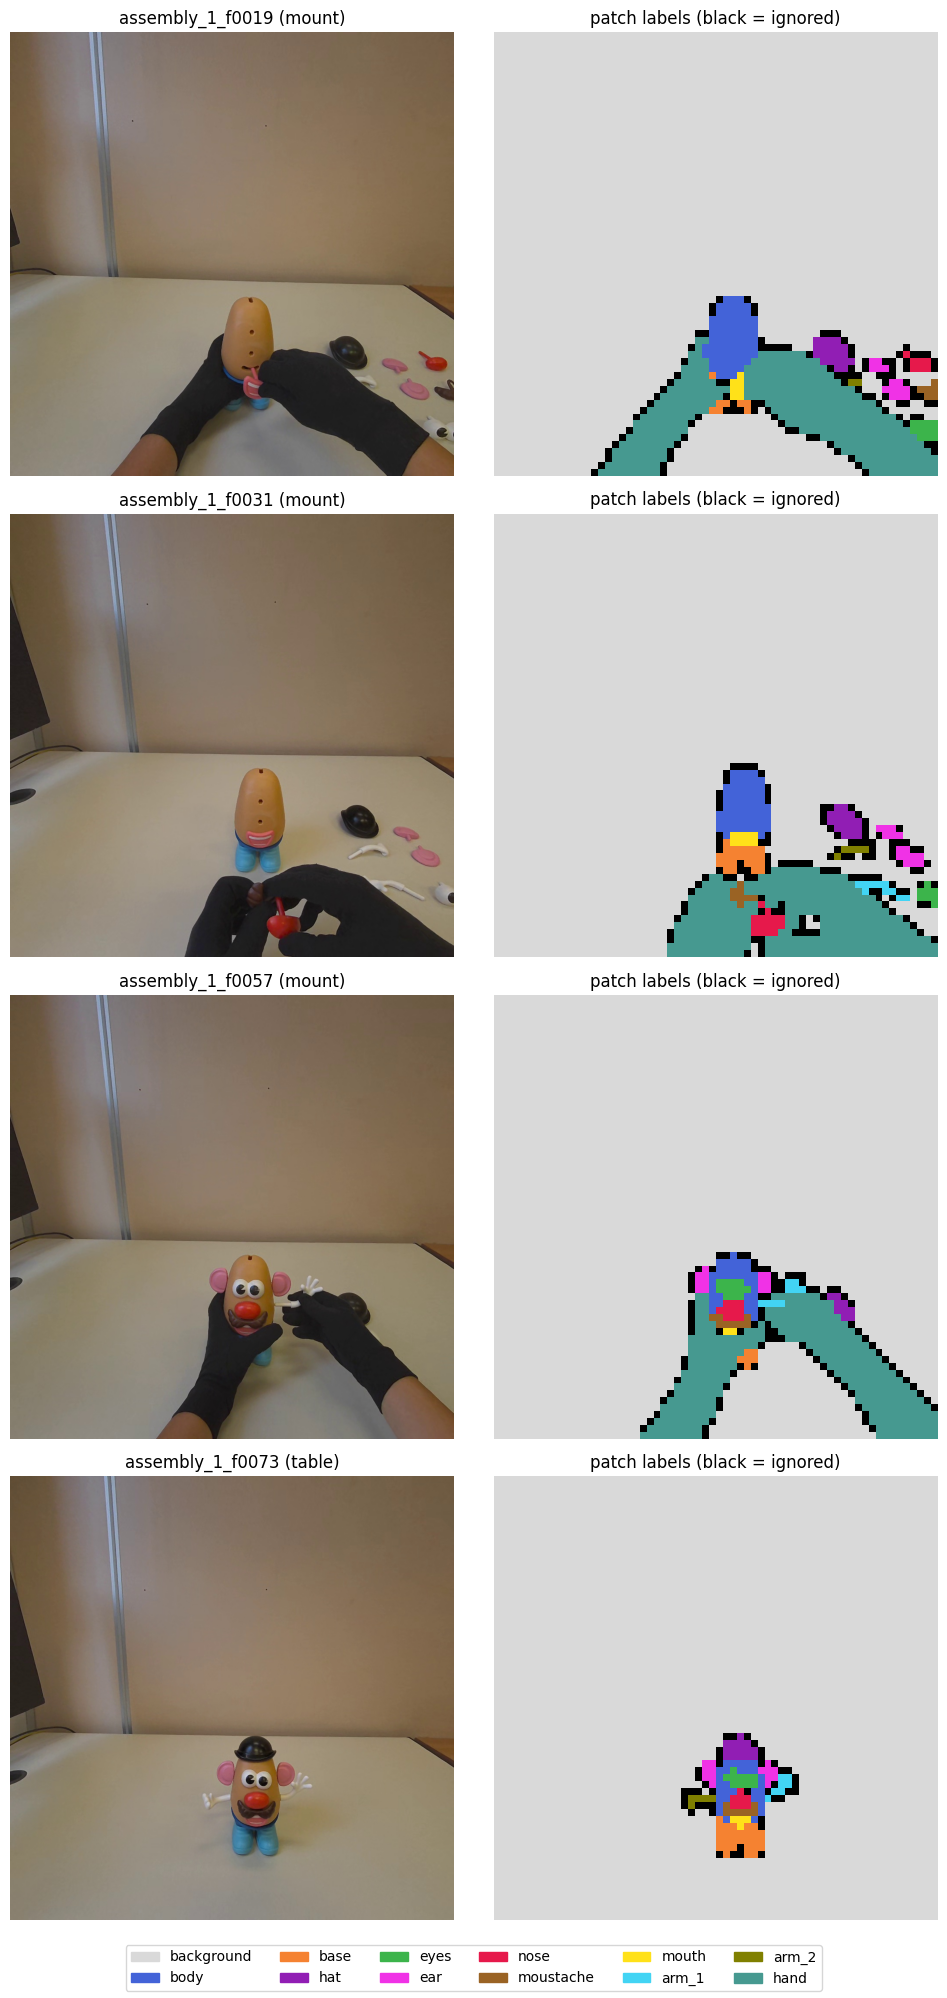

In [12]:
# 4.4 Visual check of the ground truth on four frames chosen before looking: the mouth at its slot between the hands (f0019),
# the nose threaded into the moustache in hand (f0031), arm_1 grazing the body (f0057), the corrected v1-baseline annotation (f0073)
CHECK_FRAMES = ["assembly_1_f0019", "assembly_1_f0031", "assembly_1_f0057", "assembly_1_f0073"]
by_name = {item["frame"]: item for item in TEST_FRAMES}
fig, axes = plt.subplots(len(CHECK_FRAMES), 2, figsize=(10, 5 * len(CHECK_FRAMES)))
present = set()
for row, name in zip(axes, CHECK_FRAMES):
    item = by_name[name]
    row[0].imshow(Image.open(item["image_path"]))
    row[0].set_title(f"{name} ({item['moment']})")
    row[1].imshow(label_grid_to_rgb(item["gt"]), interpolation="nearest")
    row[1].set_title("patch labels (black = ignored)")
    present |= {CLASS_NAMES[i] for i in np.unique(item["gt"]) if i != IGNORE_ID}
    for ax in row:
        ax.axis("off")
handles = [mpatches.Patch(color=CLASS_COLORS[name], label=name) for name in CLASS_NAMES if name in present]
fig.legend(handles=handles, loc="lower center", ncol=6)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

Observation 4.4: In the four frames the labels follow the rule of rasterize_annotation, the smaller polygon wins. In f0019 the mouth at its slot keeps its class over the body, and the hands around it stay hand. In f0031 the nose and the moustache joined in hand stay separate from the hands that hold them. In f0057, after the correction, the eyes, the nose and the mouth keep their class over the body, and arm_1 touching the body is labelled arm_1. In f0073 the base is labelled base, and the whole figure, seen from farther away, covers few patches per piece.

Borders between classes are ignored (black), as the labelling rule requires.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 4:

src/perception/labels.py, check_annotation, rasterize_annotation and patch_label_grid: the checks of the annotation files and the labelling rule of the pipeline (Section 5).

Russell et al. 2008, LabelMe, Sect. 3.3: overlapping polygons; an object completely contained in another one is on top.

Everingham et al. 2010, PASCAL VOC, Sect. 3.6.1 and 4.2.1: a void border around each object, excluded from the evaluation.

Support-set study on V2, Sections 3.2-3.4: the same checks and counts on the validation frames.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 5 - Measurement plan

This section fixes what is measured on the test frames and how it is reported, before any prediction on assembly_1. It is committed before Sections 6 and 7 are written and run. Nothing in it depends on a result, and no result will change the method, the support set, the frames or the annotations.

Main measure. The mIoU over the 10 pieces on all 31 frames, as in validation. For each piece, true positives, false positives and false negatives are summed over the frames before dividing (frame_miou). arm_1 and arm_2 are kept separate, since mounting one in the place of the other is an error Phase 2 must detect. Hand and background are classified but do not enter the mean. No class is excluded in any frame. The validation value is 0.779.

Descriptive measures. The mIoU of each moment: 9 table, 11 pick and 11 mount frames. The mIoU with the arms merged, where a patch of one arm predicted as the other counts as correct (merge_arms). The IoU of each piece over all frames. For each piece, the share of its patches predicted as each other class, from the confusion matrix summed over the frames, to describe the errors. The overlays of the four frames of Section 4.4 are shown, and those of all 31 frames are saved in outputs/phase_1_test; they are for description and are never used to choose anything.

Uncertainty. The bootstrap of the validation set is used unchanged (support-set study on V2, Section 1 and cell 8.3), with 1000 resamples, seed 0, and the 95% percentile interval, which drops the lowest and the highest 2.5% of the resampled values (Koehn 2004, Sect. 5). Frames close in time are not independent, and the bootstrap of single frames would give intervals that are too narrow (Künsch 1989, Sect. 1). Over all 31 frames in time order, the resamples are therefore made of overlapping blocks of 3 consecutive frames (Künsch 1989, Sect. 2.3): 11 blocks drawn among the 29 possible starts, joined and cut to 31 frames. This applies to the main measure, to the mIoU with the arms merged and to the IoU of each piece. Within a single moment the frames come from different pieces, far apart in time, and are resampled one by one. In validation the interval was on the difference between two support sets; here it is on the value of the fixed method.

Comparison with validation. The test values are reported next to those of validation: mIoU 0.779; table 0.818, pick 0.777 and mount 0.731; arms merged 0.836; and the IoU of each piece of the support-set study on V2 (Section 9.2, current support set). The comparison is descriptive. The two sets have different frames, and the validation values are optimistic, since they were used to choose the method (Cawley and Talbot 2010, Sect. 5). No statistical test is made between them; whether a validation value falls inside the test interval is described, not used to decide anything.

Expectations, written as hypotheses before the run, from the known limits of the method. The test values are lower than those of validation. arm_2 has the lowest IoU of the pieces, and arm_1 and arm_2 are confused, so the gap between the mIoU with the arms merged and the mIoU over the 10 pieces is at least as large as in validation (0.057). The mouth is partly taken for the nose. An arm just picked (f0055, f0060) is partly missed. The small pieces of f0073, where the figure is seen from farther away, are partly lost. These hypotheses are checked in Section 8, for description only.

Single execution. Section 7 is run once, on the committed notebook. The run counts as done as soon as any metric is displayed. If it stops earlier for a technical reason, such as memory or power, it is restarted without changes and the stop is reported. After the metrics are shown, no code, setting, frame or annotation is changed. If an error in the evaluation code is found after the run, it is corrected, both values are reported and the correction is explained. The predictions, labels and similarities of every frame, are saved in outputs/phase_1_test, so that Section 8 and Phase 2 read them and never run the test again.

What is not done. No other frame of assembly_1 is evaluated quantitatively, and no subset of frames or pieces is chosen after the results are seen.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 5:

Künsch 1989, Sect. 1: the bootstrap assumes independent observations, and gives incorrect answers if dependence is neglected. Sect. 2.3: the resamples are made of blocks of consecutive observations, drawn at random with replacement.

Koehn 2004, Sect. 5: bootstrap resampling of the test set; dropping the top and the bottom 2.5% of the resampled scores gives the 95% confidence interval.

Cawley and Talbot 2010, Sect. 5: a performance estimate on data used for selection is optimistically biased.

Support-set study on V2, Section 1 and cell 8.3: the block bootstrap used in validation. Section 9.2: the IoU of each piece in validation, current support set.

Pipeline (phase_1_perception.ipynb), regression check at v1.9-pipeline: mIoU 0.779; table 0.818, pick 0.777, mount 0.731; arms merged 0.836.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 6 - Prototypes

This section loads the V2 prototypes saved by the pipeline (Section 6.4) and checks them, without running any prediction.

The checks compare the metadata saved with the prototypes against the settings of this notebook: the class order, the background margin, the labelling rule, the model and the patch size. They also check that every prototype is a unit vector with a class, that every class has prototypes, and that no reference frame comes from assembly_1 or assembly_2, so the test frames never contributed to the prototypes.

The file is in outputs/, which is not tracked by git. Its SHA-256 fingerprint is printed, so the notebook records which file was used.

In [13]:
# 6.1 Load the saved V2 prototypes and check them against the settings of this notebook
saved = load_patch_prototypes(PROTOTYPES_PATH)
meta, vectors, owners = saved["metadata"], saved["prototypes"], saved["owners"]
reference_sequences = {sequence_of(ref["frame"]) for ref in meta["reference_frames"]}

checks = {
    "class names in the order of CLASS_NAMES": saved["class_names"] == CLASS_NAMES,
    "margin = MARGIN": meta["margin"] == MARGIN,
    "min_label_coverage = MIN_LABEL_COVERAGE": meta["min_label_coverage"] == MIN_LABEL_COVERAGE,
    "model = MODEL_DIR": meta["model"] == MODEL_DIR.name,
    "patch size = PATCH_SIZE": meta["patch_size"] == PATCH_SIZE,
    "feature dimension = width of the vectors": meta["feature_dim"] == vectors.shape[1],
    "one class per prototype": len(owners) == len(vectors),
    "unit vectors (tolerance 1e-4)": bool(np.allclose(np.linalg.norm(vectors, axis=1), 1.0, atol=1e-4)),
    "every class has prototypes": set(np.unique(owners).tolist()) == set(range(len(CLASS_NAMES))),
    "no reference frame from assembly_1 or assembly_2": not (reference_sequences & {"assembly_1", "assembly_2"}),
}
display(pd.Series(checks, name="passed").to_frame())
assert all(checks.values()), "The saved prototypes do not match the settings of this notebook"

fingerprint = hashlib.sha256(PROTOTYPES_PATH.read_bytes()).hexdigest()[:12]
print(f"File: {PROTOTYPES_PATH.name}, {PROTOTYPES_PATH.stat().st_size / 2**20:.0f} MB, SHA-256 {fingerprint}, created {meta['created']}")
print(f"Method: {meta['method']}")
print(f"{len(vectors)} prototypes of dimension {vectors.shape[1]}, from {len(meta['reference_frames'])} reference frames")

display(pd.DataFrame(meta["reference_frames"]).set_index("frame")[["role", "annotation"]])
counts = pd.Series(np.bincount(owners, minlength=len(CLASS_NAMES)), index=CLASS_NAMES, name="prototypes")
display(counts.to_frame().T)

# Prototypes sorted by class, as class_similarities_gpu requires (Section 7); sorting does not change the maxima per class
PROTOTYPES_SORTED = sort_by_class(vectors, owners)

,passed
class names in the order of CLASS_NAMES,True
margin = MARGIN,True
min_label_coverage = MIN_LABEL_COVERAGE,True
model = MODEL_DIR,True
patch size = PATCH_SIZE,True
feature dimension = width of the vectors,True
one class per prototype,True
unit vectors (tolerance 1e-4),True
every class has prototypes,True
no reference frame from assembly_1 or assembly_2,True


File: patch_prototypes.npz, 172 MB, SHA-256 ab0f13579f17, created 2026-10-21 19:04
Method: V2: every labelled reference patch is a prototype; nearest neighbour by cosine similarity
39125 prototypes of dimension 1152, from 10 reference frames


,role,annotation
frame,,
5_assembled_f0002,assembled,data/extracted_frames/5_assembled_f0002.json
caos_f0149,partially assembled,data/extracted_frames/caos_f0149.json
5_assembled_f0019,"assembled, 3/4 view",data/extracted_frames/5_assembled_f0019.json
3_disassembled_ordered_f0001,disassembled,data/extracted_frames/3_disassembled_ordered_f...
2_disassembled_caos_f0016,"disassembled, top-down view",data/extracted_frames/2_disassembled_caos_f001...
Take_3_1_Base_f0099,"base only, upright",data/extracted_frames/Take_3_1_Base_f0099.json
Take_3_1_Base_f0131,"base only, lying",data/extracted_frames/Take_3_1_Base_f0131.json
caos_f0211,hands,data/annotation_versions/margin_study/caos_f02...
4_partially_assembled_f0002,"body on base, face incomplete; mouth loose at 3/4",data/extracted_frames/4_partially_assembled_f0...


,background,body,base,hat,eyes,ear,nose,moustache,mouth,arm_1,arm_2,hand
prototypes,37864,302,201,52,32,52,29,35,28,33,15,482


Observation 6.1: All ten checks pass. The file holds 39,125 prototypes of dimension 1152, built from the 10 reference frames of the pipeline, none of them from assembly_1 or assembly_2; caos_f0211 is read from the archived annotation used by the studies. The metadata match the settings of this notebook: class order, margin 0, coverage 0.5, model and patch size 16. The file takes 172 MB, has SHA-256 ab0f13579f17 and was created on 2026-10-21 at 19:04.

Background has 37,864 prototypes, hand 482 and body 302. The other pieces have between 52 (hat and ear) and 15 (arm_2). arm_2, the piece with the lowest IoU in validation (0.380), is also the one with the fewest prototypes.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 6:

Pipeline (phase_1_perception.ipynb), Section 6.4: the V2 prototypes saved with the class of each one and their metadata, then reloaded and compared.

src/perception/prototypes.py, load_patch_prototypes and sort_by_class: loading the file and ordering the prototypes by class for the GPU.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 7 - Predictions and metrics

This section runs the fixed method on the 31 test frames, once, and measures it as planned in Section 5.

The computation is that of the pipeline on the validation frames (Sections 9 and 10), with the same functions of src/perception. Each patch takes the class of its most similar prototype, with background margin 0. The mIoU sums the counts over the frames before dividing. The intervals use the block bootstrap of the support-set study on V2 (cell 8.3), applied here to the value of the fixed method.

Cell 7.2 saves the labels and the similarities of every frame in outputs/phase_1_test/predictions.npz, with the git commit and the fingerprint of the prototypes. Later analyses read this file and never run the test again. The first metric is shown in 7.3: from that cell on, the run counts as done (Section 5).

In [14]:
# 7.1 Model, prototypes on the GPU, and the GPU/CPU check of the pipeline (9.1) on the first test frame
from perception.prototypes import class_similarities

RUN_COMMIT = git("rev-parse", "--short", "HEAD").strip()
print(f"Git commit of this run: {RUN_COMMIT}")
assert not git("status", "--porcelain", "--", *json_paths).strip(), "Test annotations differ from the last commit"

extractor = FeatureExtractor(MODEL_DIR, device=DEVICE, dtype=DTYPE)
assert extractor.patch_size == PATCH_SIZE, f"Model patch size {extractor.patch_size}, ground truth built with {PATCH_SIZE}"
assert tuple(extractor.input_size(*INPUT_SIZE)) == INPUT_SIZE, "The model would resize the frames: ground truth and predictions would not match"

PROTOTYPES_GPU = tuple(torch.as_tensor(array, device=DEVICE) for array in PROTOTYPES_SORTED)

first = TEST_FRAMES[0]
check_features, _ = extractor.extract(Image.open(first["image_path"]).convert("RGB"))
labels_gpu = assign_labels(class_similarities_gpu(check_features, *PROTOTYPES_GPU), MARGIN)
labels_cpu = assign_labels(class_similarities(check_features, *PROTOTYPES_SORTED), MARGIN)
different = int((labels_gpu != labels_cpu).sum())
print(f"{first['frame']}: {different} of {labels_gpu.size} patches differ between GPU and CPU")
assert different == 0

Git commit of this run: 6ab690f


Loading weights:   0%|          | 0/330 [00:00<?, ?it/s]

assembly_1_f0002: 0 of 4096 patches differ between GPU and CPU


Observation 7.1: The run uses commit 6ab690f, and the test annotations are the committed ones. On assembly_1_f0002 the GPU and the CPU give the same label to all 4096 patches.

In [15]:
# 7.2 Classify the 31 test frames (pipeline 9.2), compute the confusion matrices and save everything; no metric is shown here
results = {}
start = time.time()
for item in TEST_FRAMES:
    features, resized_size = extractor.extract(Image.open(item["image_path"]).convert("RGB"))
    assert tuple(resized_size) == INPUT_SIZE
    similarities = class_similarities_gpu(features, *PROTOTYPES_GPU)
    results[item["frame"]] = {"labels": assign_labels(similarities, MARGIN), "similarities": similarities}
elapsed = time.time() - start

CONFUSIONS = [confusion_matrix(item["gt"], results[item["frame"]]["labels"]) for item in TEST_FRAMES]

run_info = {"git_commit": RUN_COMMIT, "prototypes_sha256": fingerprint, "margin": MARGIN,
            "min_label_coverage": MIN_LABEL_COVERAGE, "run": time.strftime("%Y-%m-%d %H:%M")}
np.savez_compressed(
    OUTPUT_DIR / "predictions.npz",
    class_names=np.array(CLASS_NAMES),
    frames=np.array([item["frame"] for item in TEST_FRAMES]),
    moments=np.array([item["moment"] for item in TEST_FRAMES]),
    confusions=np.stack(CONFUSIONS),
    run_info=json.dumps(run_info),
    **{f"{frame}__labels": r["labels"].astype(np.int64) for frame, r in results.items()},
    **{f"{frame}__similarities": r["similarities"].astype(np.float32) for frame, r in results.items()},
)
print(f"{len(results)} frames classified in {elapsed:.0f} s ({elapsed / len(results):.2f} s per frame)")
print(f"Saved to {OUTPUT_DIR / 'predictions.npz'}: {run_info}")

31 frames classified in 14 s (0.46 s per frame)
Saved to c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\phase_1_test\predictions.npz: {'git_commit': '6ab690f', 'prototypes_sha256': 'ab0f13579f17', 'margin': 0.0, 'min_label_coverage': 0.5, 'run': '2026-10-25 10:43'}


Observation 7.2: The 31 test frames were classified in 14 s, 0.46 s per frame, consistent with the cost measured in the pipeline. Labels, similarities and confusion matrices are saved with the commit (6ab690f) and the fingerprint of the prototypes (ab0f13579f17). The notebook was run once, from top to bottom, with execution counts 1 to 18 in order.

In [16]:
# 7.3 Main measure and descriptive mIoU, with 95% bootstrap intervals (Section 5), next to the validation values
MOMENTS = ["table", "pick", "mount"]
MOMENT_FRAMES = {m: [k for k, item in enumerate(TEST_FRAMES) if item["moment"] == m] for m in MOMENTS}

n = len(TEST_FRAMES)
rng = np.random.default_rng(RANDOM_SEED)
starts = rng.integers(0, n - BLOCK + 1, size=(N_BOOTSTRAP, int(np.ceil(n / BLOCK))))
BLOCK_RESAMPLES = np.array([np.concatenate([np.arange(s, s + BLOCK) for s in row])[:n] for row in starts])
MOMENT_RESAMPLES = {m: np.array(MOMENT_FRAMES[m])[rng.integers(0, len(MOMENT_FRAMES[m]), size=(N_BOOTSTRAP, len(MOMENT_FRAMES[m])))]
                    for m in MOMENTS}

VALIDATION_MIOU = {"all frames": 0.779, "table": 0.818, "pick": 0.777, "mount": 0.731, "arms merged": 0.836}
rows = {}
for label, frames, resamples, merge, scheme in (
        [("all frames", None, BLOCK_RESAMPLES, False, f"blocks of {BLOCK}")]
        + [(m, MOMENT_FRAMES[m], MOMENT_RESAMPLES[m], False, "single frames") for m in MOMENTS]
        + [("arms merged", None, BLOCK_RESAMPLES, True, f"blocks of {BLOCK}")]):
    low, high = percentile_interval(bootstrap_miou(CONFUSIONS, EXCLUDED, resamples, merge=merge))
    rows[label] = {"frames": n if frames is None else len(frames), "test": frame_miou(CONFUSIONS, EXCLUDED, frames, merge=merge),
                   "95% low": low, "95% high": high, "validation": VALIDATION_MIOU[label], "resampling": scheme}
MIOU_TABLE = pd.DataFrame(rows).T
display(MIOU_TABLE.round({"test": 3, "95% low": 3, "95% high": 3}))

,frames,test,95% low,95% high,validation,resampling
all frames,31,0.764799,0.719431,0.795907,0.779,blocks of 3
table,9,0.834853,0.814204,0.858013,0.818,single frames
pick,11,0.705966,0.641889,0.777639,0.777,single frames
mount,11,0.781545,0.728075,0.820802,0.731,single frames
arms merged,31,0.819456,0.784548,0.845169,0.836,blocks of 3


Observation 7.3: The mIoU over the 10 pieces on the 31 test frames is 0.765, with 95% interval 0.719-0.796. The validation value, 0.779, lies inside it.

By moment, the mIoU is 0.835 at the table (0.814-0.858), 0.706 at the pick (0.642-0.778) and 0.782 at the mounting (0.728-0.821). The validation values, 0.818, 0.777 and 0.731, lie inside the three intervals, each close to one end. With the arms merged the mIoU is 0.819 (0.785-0.845), against 0.836 in validation.

The order of the moments differs from validation. There the mounting was the weakest moment; here the pick is, and the mounting is higher than in validation. The interval of the pick is also the widest, 0.136, so the pick is the least precise of the three measures.

These intervals describe the variation over frames of this recording. They do not include the variation between recordings, operators or scenes, which a single test video cannot measure.

In [17]:
# 7.4 IoU of each piece over all frames, with 95% intervals (blocks of 3) and the validation values; IoU by moment;
# where the patches of each piece go (share of its annotated patches, confusion matrix summed over the frames)
VALIDATION_IOU = {"body": 0.880, "base": 0.906, "hat": 0.925, "eyes": 0.867, "ear": 0.897, "nose": 0.742,
                  "moustache": 0.790, "mouth": 0.662, "arm_1": 0.741, "arm_2": 0.380, "hand": 0.975}
shown = [name for name in CLASS_NAMES if name in VALIDATION_IOU]
ids = [CLASS_NAMES.index(name) for name in shown]

iou = frame_iou(CONFUSIONS, EXCLUDED)
low, high = percentile_interval(bootstrap_class_iou(CONFUSIONS, EXCLUDED, BLOCK_RESAMPLES))
IOU_TABLE = pd.DataFrame({"test": iou[ids], "95% low": low[ids], "95% high": high[ids],
                          "validation": [VALIDATION_IOU[name] for name in shown]}, index=shown)
display(IOU_TABLE.round(3))

by_moment = pd.DataFrame({m: frame_iou(CONFUSIONS, EXCLUDED, MOMENT_FRAMES[m])[ids] for m in MOMENTS}, index=shown)
print("IoU by moment:")
display(by_moment.round(3))

total = np.sum(CONFUSIONS, axis=0)
shares = pd.DataFrame(100 * total[ids] / total[ids].sum(axis=1, keepdims=True), index=shown, columns=CLASS_NAMES)
print("Where the annotated patches of each class go (% of its patches; rows = ground truth, columns = prediction):")
display(shares.round(1))

,test,95% low,95% high,validation
body,0.864,0.819,0.901,0.880
base,0.909,0.869,0.938,0.906
hat,0.905,0.847,0.951,0.925
eyes,0.815,0.747,0.873,0.867
ear,0.892,0.853,0.922,0.897
nose,0.721,0.598,0.813,0.742
moustache,0.766,0.700,0.822,0.790
mouth,0.626,0.473,0.739,0.662
arm_1,0.733,0.631,0.810,0.741
arm_2,0.416,0.241,0.562,0.380


IoU by moment:


,table,pick,mount
body,0.919,0.860,0.825
base,0.959,0.872,0.914
hat,0.975,0.863,0.884
eyes,0.909,0.740,0.791
ear,0.950,0.894,0.843
nose,0.821,0.592,0.802
moustache,0.792,0.779,0.719
mouth,0.684,0.493,0.786
arm_1,0.818,0.650,0.788
arm_2,0.522,0.317,0.464


Where the annotated patches of each class go (% of its patches; rows = ground truth, columns = prediction):


,background,body,base,hat,eyes,ear,nose,moustache,mouth,arm_1,arm_2,hand
body,0.2,92.2,1.5,0.1,1.2,0.1,1.1,0.2,0.7,0.0,0.0,2.8
base,0.2,0.9,96.8,1.2,0.0,0.0,0.0,0.0,0.7,0.0,0.0,0.1
hat,1.0,1.2,1.5,94.8,0.0,0.6,0.0,0.0,0.0,0.0,0.0,0.8
eyes,2.6,5.9,0.0,0.0,86.3,3.3,0.0,0.0,0.7,1.3,0.0,0.0
ear,0.3,4.2,0.0,0.0,0.0,94.4,0.0,0.0,0.0,0.0,0.0,1.1
nose,0.0,0.0,0.5,0.0,0.0,2.4,86.6,6.7,1.9,0.5,0.0,1.4
moustache,0.0,5.4,1.0,0.0,0.0,1.0,0.5,87.2,4.4,0.0,0.0,0.5
mouth,0.0,3.4,0.0,0.0,0.0,0.8,16.1,1.7,78.0,0.0,0.0,0.0
arm_1,0.8,0.4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,98.4,0.0,0.4
arm_2,14.6,0.0,0.0,0.0,0.0,0.0,0.0,0.7,0.0,43.1,41.6,0.0


Observation 7.4: Over all frames, base (0.909), hat (0.905), ear (0.892), body (0.864) and eyes (0.815) have the highest IoU; moustache (0.766), arm_1 (0.733), nose (0.721) and mouth (0.626) follow, and arm_2 is the weakest piece (0.416). Hand reaches 0.971. The validation value of every class lies inside its test interval. The largest differences from validation are eyes (0.815 against 0.867) and arm_2 (0.416 against 0.380).

By moment, most pieces are best at the table. At the pick nose falls to 0.592, mouth to 0.493 and arm_2 to 0.317, and eyes to 0.740. At the mounting nose (0.802) and mouth (0.786) are close to their table values.

The errors are those already seen in validation. Of the arm_2 patches, 41.6% are correct, 43.1% are predicted as arm_1 and 14.6% as background. Of the mouth patches, 16.1% are predicted as nose. Of the nose patches, 6.7% are predicted as moustache. Of the eyes patches, 5.9% are predicted as body and 3.3% as ear. Few patches of the pieces are lost to the hand: at most 2.8%, for the body.

Overlays of 31 frames saved to c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\phase_1_test\overlays


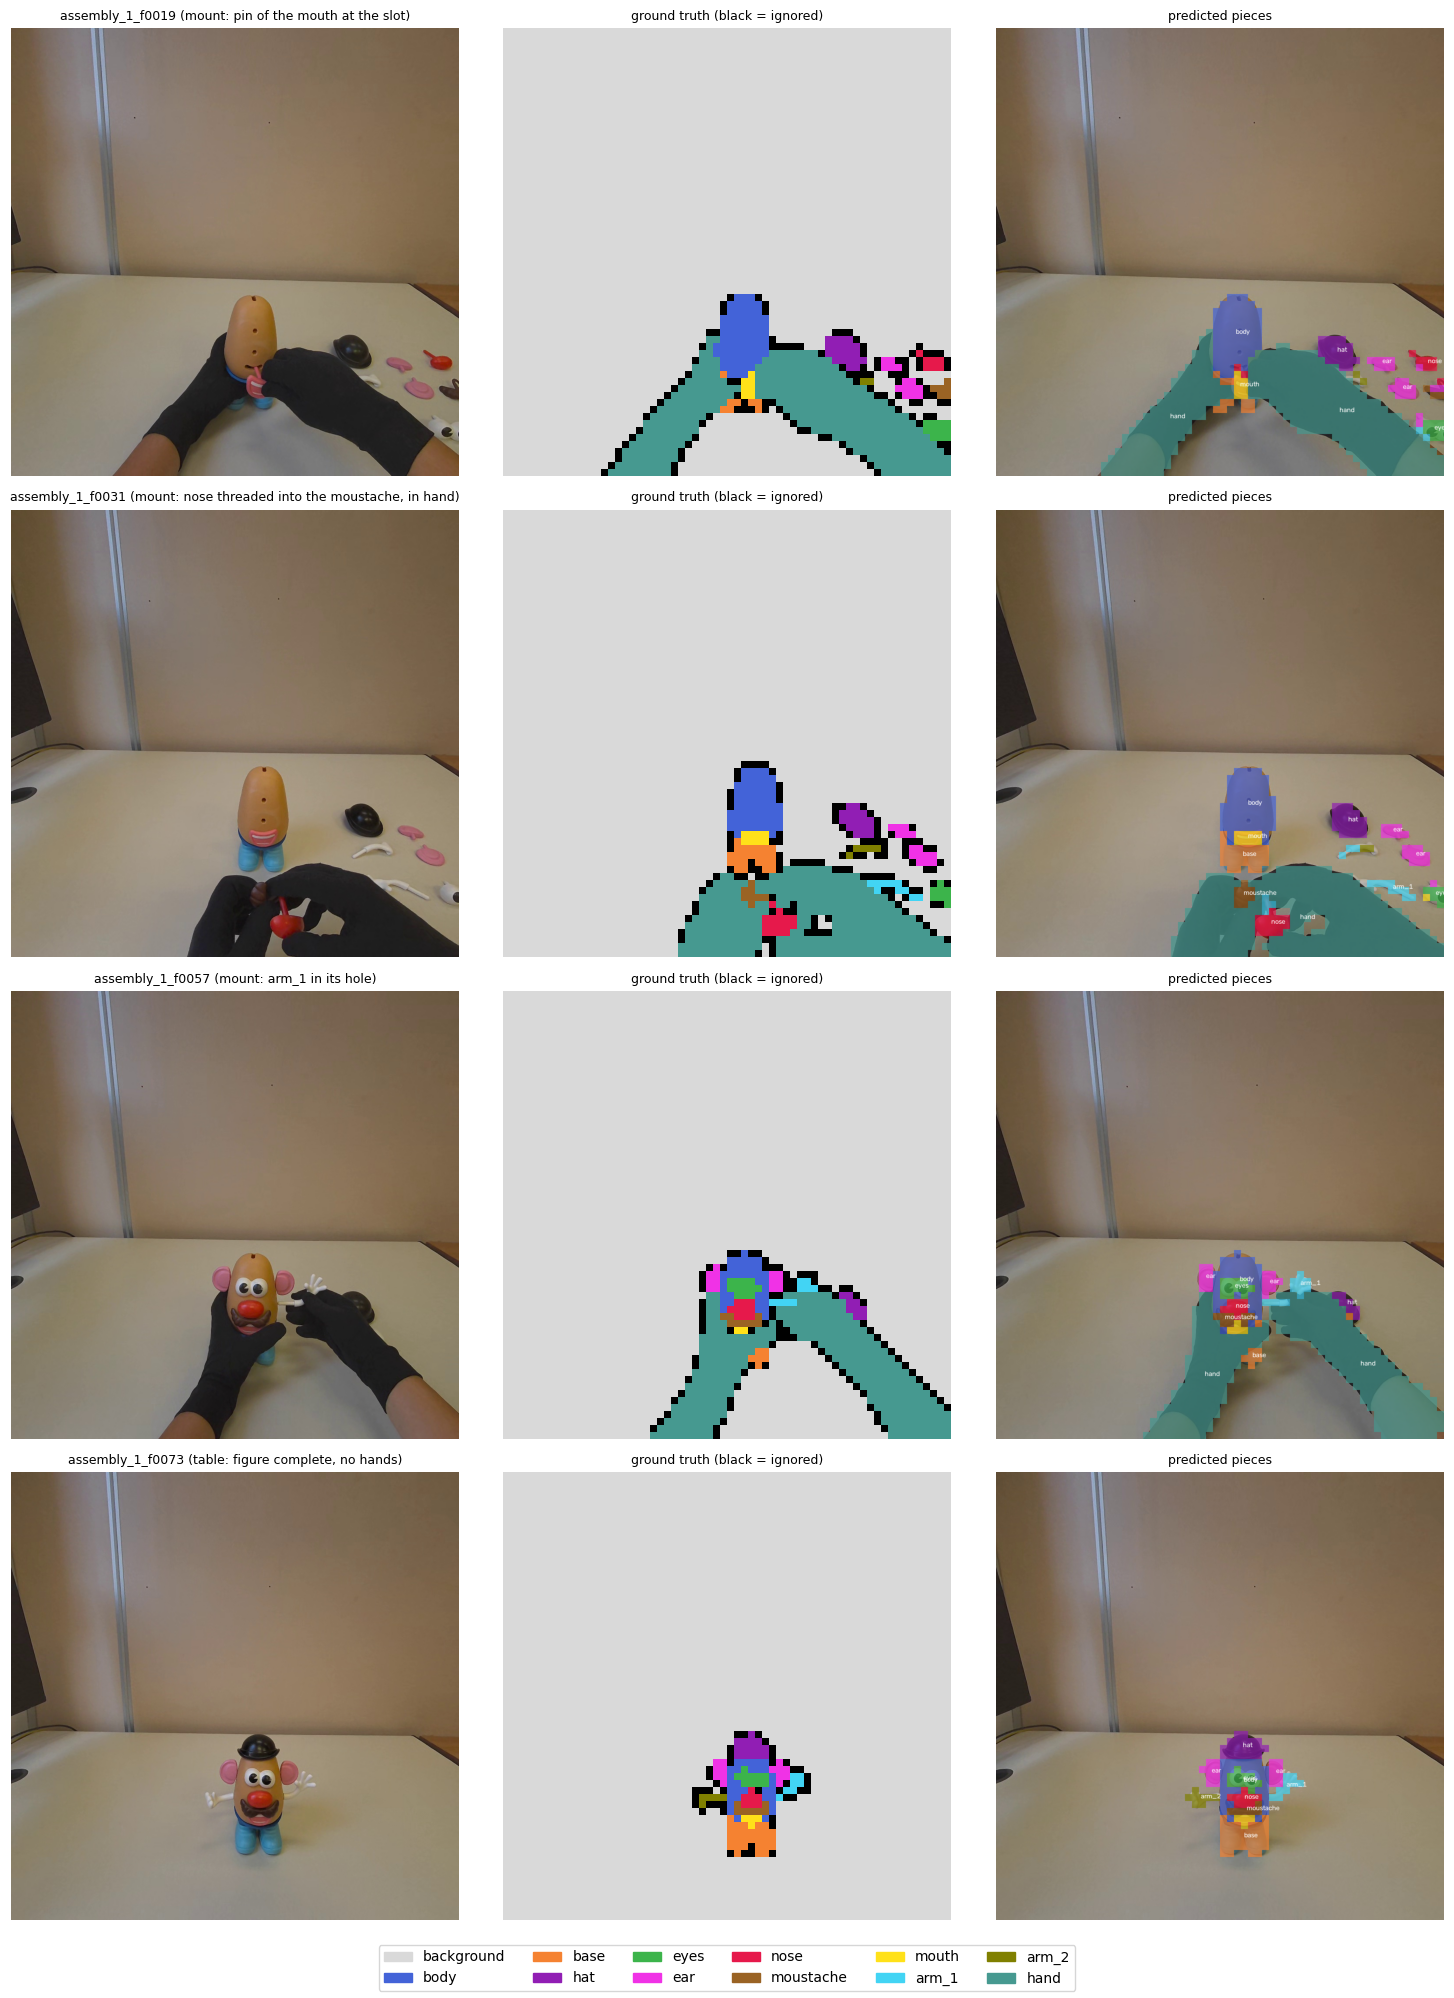

In [18]:
# 7.5 Predicted labels on the four frames of Section 4.4 (pipeline 10.2); the overlays of all 31 frames are saved
OVERLAY_DIR = OUTPUT_DIR / "overlays"
OVERLAY_DIR.mkdir(exist_ok=True)
for item in TEST_FRAMES:
    image = np.asarray(Image.open(item["image_path"]).convert("RGB"))
    Image.fromarray(render_overlay(image, results[item["frame"]]["labels"], MIN_BLOB_PATCHES)).save(OVERLAY_DIR / f"{item['frame']}.png")
print(f"Overlays of {len(TEST_FRAMES)} frames saved to {OVERLAY_DIR}")

legend = [mpatches.Patch(color=CLASS_COLORS[name], label=name) for name in CLASS_NAMES]
fig, axes = plt.subplots(len(CHECK_FRAMES), 3, figsize=(15, 5 * len(CHECK_FRAMES)))
for row, name in zip(axes, CHECK_FRAMES):
    item = by_name[name]
    image = np.asarray(Image.open(item["image_path"]).convert("RGB"))
    row[0].imshow(image)
    row[0].set_title(f"{name} ({item['moment']}: {item['note']})", fontsize=9)
    row[1].imshow(label_grid_to_rgb(item["gt"]), interpolation="nearest")
    row[1].set_title("ground truth (black = ignored)", fontsize=9)
    row[2].imshow(render_overlay(image, results[name]["labels"], MIN_BLOB_PATCHES))
    row[2].set_title("predicted pieces", fontsize=9)
    for ax in row:
        ax.axis("off")
fig.legend(handles=legend, loc="lower center", ncol=6)
plt.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(OUTPUT_DIR / "test_predictions.png", dpi=100, bbox_inches="tight")
plt.show()

Observation 7.5: In the four frames the predicted pieces follow the ground truth in position and shape. In f0019 the mouth at its slot is found between the hands, and the loose pieces on the table at the right are labelled. In f0031 the nose and the moustache joined in hand are found under the hands. In f0057 the face pieces and arm_1 at the side of the body are found. In f0073, where the figure is seen from farther away, all pieces are found, both arms included. These four frames are a description, not a measure: the measure is in 7.3 and 7.4.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 7:

Pipeline (phase_1_perception.ipynb), Sections 9.1, 9.2, 10.1 and 10.2: the same classification, GPU/CPU check, metrics and overlays on the validation frames.

Support-set study on V2, cell 8.3: the block and single-frame resamples, built here with the same code and seed. Section 9.2: the IoU of each piece in validation.

Künsch 1989, Sect. 2.3, and Koehn 2004, Sect. 5: block bootstrap and 95% percentile interval (Section 5).

------------------------------------------------------------------------------------------------------------------------------------------

## Section 8 - Video of assembly_1 (description only)

This section runs the pipeline on the whole test video, after the measure of Section 7 was made and committed. It is a description: no number is computed from it, and nothing in Phase 1 changes because of it.

The decision behind it was taken after the measure. Phase 2 needs recordings with assembly errors, which assembly_1 and assembly_2 do not contain, and a test video not looked at while the method is designed. Phase 2 will therefore be tested on new recordings, made with a phone mounted to simulate the headset, and assembly_1 becomes development material for Phase 2, like assembly_2. The new recordings will also have a different scene, outside the laboratory.

The code and the parameters are those of the pipeline (Section 11). C-RADIO runs once each time the scene becomes still, that is when the motion score stays below MOTION_THRESHOLD for STABLE_FRAMES_NEEDED consecutive frames, and its prediction is shown while the scene stays still. These parameters are provisional: they were set by watching assembly_2 and not measured against annotated pauses.

Cells 8.4 and 8.5 run perception on every frame, offline, as a second description. They show what the gating hides, the picks and the mountings, and they save the labels of every frame as development material for Phase 2.

In [30]:
# 8.1 Video pipeline of Section 11 of the pipeline, on assembly_1: C-RADIO runs once each time the scene becomes still
def motion_score(prev_gray, gray):
    """Mean absolute grey-level difference (0-255) between two consecutive downscaled frames."""
    return float(np.abs(gray.astype(np.float32) - prev_gray.astype(np.float32)).mean())


cap = cv2.VideoCapture(str(VIDEO_PATH))
fps = cap.get(cv2.CAP_PROP_FPS)
width, height = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
output_video = OUTPUT_DIR / f"{VIDEO_PATH.stem}_perception.mp4"
writer = cv2.VideoWriter(str(output_video), cv2.VideoWriter_fourcc(*"mp4v"), fps, (width, height))

prev_gray, still_count, current_labels = None, 0, None
video_log, snapshots, motion_scores = [], [], []
frame_index = 0
while True:
    ok, frame_bgr = cap.read()
    if not ok:
        break
    frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    gray = cv2.resize(cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2GRAY), MOTION_SIZE)
    score = motion_score(prev_gray, gray) if prev_gray is not None else np.inf
    motion_scores.append(score)
    still_count = still_count + 1 if score < MOTION_THRESHOLD else 0
    prev_gray = gray

    if still_count == STABLE_FRAMES_NEEDED:          # the scene has just become still: run C-RADIO once
        features, _ = extractor.extract(Image.fromarray(frame_rgb))
        current_labels = assign_labels(class_similarities_gpu(features, *PROTOTYPES_GPU), MARGIN)
        counts = {CLASS_NAMES[i]: int((current_labels == i).sum()) for i in range(len(CLASS_NAMES))}
        video_log.append({
            "frame": frame_index,
            "time (s)": round(frame_index / fps, 2),
            "pieces seen": ", ".join(n for n, c in counts.items()
                                     if n not in (BACKGROUND_LABEL, HAND_LABEL) and c >= MIN_BLOB_PATCHES),
        })
        snapshots.append((frame_index, render_overlay(frame_rgb, current_labels, MIN_BLOB_PATCHES)))
    elif still_count < STABLE_FRAMES_NEEDED:
        current_labels = None                        # moving: no prediction is shown

    shown = render_overlay(frame_rgb, current_labels, MIN_BLOB_PATCHES) if current_labels is not None else frame_rgb.copy()
    status = "STILL - perception active" if current_labels is not None else "MOVING"
    cv2.putText(shown, status, (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 2, cv2.LINE_AA)
    writer.write(cv2.cvtColor(shown, cv2.COLOR_RGB2BGR))
    frame_index += 1

cap.release()
writer.release()
print(f"{frame_index} frames processed, C-RADIO run {len(video_log)} times. Video saved to {output_video}")
pd.set_option("display.max_colwidth", None)
display(pd.DataFrame(video_log))

2348 frames processed, C-RADIO run 25 times. Video saved to c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\phase_1_test\assembly_1_perception.mp4


,frame,time (s),pieces seen
0,67,2.23,"body, hat, eyes, ear, nose, moustache, mouth, arm_1"
1,136,4.53,"base, hat, eyes, ear, nose, moustache, arm_1"
2,196,6.53,"body, base, hat, eyes, ear, nose, moustache, arm_1"
3,216,7.20,"body, base, hat, eyes, ear, nose, moustache, arm_1"
4,222,7.40,"body, base, hat, eyes, ear, nose, moustache, arm_1"
5,435,14.50,"body, base, hat, eyes, ear, nose, moustache, arm_1"
6,459,15.30,"body, base, hat, eyes, ear, nose, moustache, arm_1"
7,525,17.50,"body, base, hat, eyes, ear, nose, moustache, arm_1"
8,646,21.54,"body, base, hat, eyes, ear, nose, mouth, arm_1"
9,715,23.84,"body, base, hat, eyes, ear, nose, moustache, mouth, arm_1"


Observation 8.1: In 78 s of video (2348 frames at 30 fps), C-RADIO runs 25 times, against 33 on assembly_2. Every pause of the event log contains at least one run: 2.2 s (0-3.7 s), 6.5-7.4 s (5.5-10.1 s), 14.5-17.5 s (13.4-17.9 s), 23.8 s (22.7-26.5 s), 35.8-37.2 s (34.8-38.5 s), 41.8-43.3 s (41.2-44.6 s), 53.4-54.0 s (52.5-54.8 s), 63.8 s (62.8-66.4 s) and 72.3 s (71.2-74.4 s). Five runs fall while hands hold a piece still: 4.5 s (base being placed), 21.5 s (mouth), 27.1 s (moustache just picked), 40.6 s (eyes) and 69.5 s (hat in hand); and two after the head turn, 77.2 and 77.7 s, when the figure is seen from another viewpoint.

The "pieces seen" column is the rough indicator of the pipeline: a class is listed when it has at least 5 patches. arm_2 is never listed while both arms lie on the table, and appears from 63.8 s, once the arms are mounted, as on assembly_2 and consistent with the arm_2 patches predicted as arm_1 in Section 7.4. The base is missing at 2.2 s, when it is still outside the frame.

Cells 2.2 to 2.5 were run again after Section 7, only to add the import of cv2, the path of the video and its parameters; Section 7 was not run again.

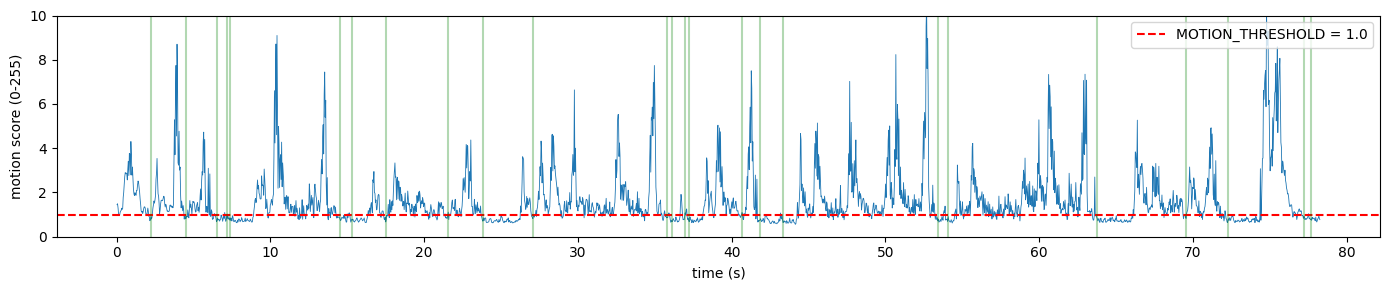

Frames below the threshold: 33%
Motion score percentiles 10/50/90: [0.72 1.24 3.07]


In [31]:
# 8.2 Motion score over the video, with the threshold and the C-RADIO runs (pipeline 11.2, continued)
times = np.arange(len(motion_scores)) / fps
fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(times, motion_scores, linewidth=0.6)
ax.axhline(MOTION_THRESHOLD, color="red", linestyle="--", label=f"MOTION_THRESHOLD = {MOTION_THRESHOLD}")
for run in video_log:
    ax.axvline(run["time (s)"], color="green", alpha=0.3)
ax.set_ylim(0, 10)
ax.set_xlabel("time (s)")
ax.set_ylabel("motion score (0-255)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

finite = np.array([s for s in motion_scores if np.isfinite(s)])
print(f"Frames below the threshold: {(finite < MOTION_THRESHOLD).mean():.0%}")
print(f"Motion score percentiles 10/50/90: {np.percentile(finite, [10, 50, 90]).round(2)}")

Observation 8.2: The motion score is below the threshold in 33% of the frames (38% on assembly_2), with percentiles 0.72, 1.24 and 3.07 at 10%, 50% and 90%. The peaks above 5 are the large movements of the hands and of the head, the largest around 75 s, when the head turns to the monitor. Between peaks the score often stays just above the threshold, between 1 and 2, so a pause starts the gating only if the head is also still. The threshold was set on assembly_2 and is not tuned here.

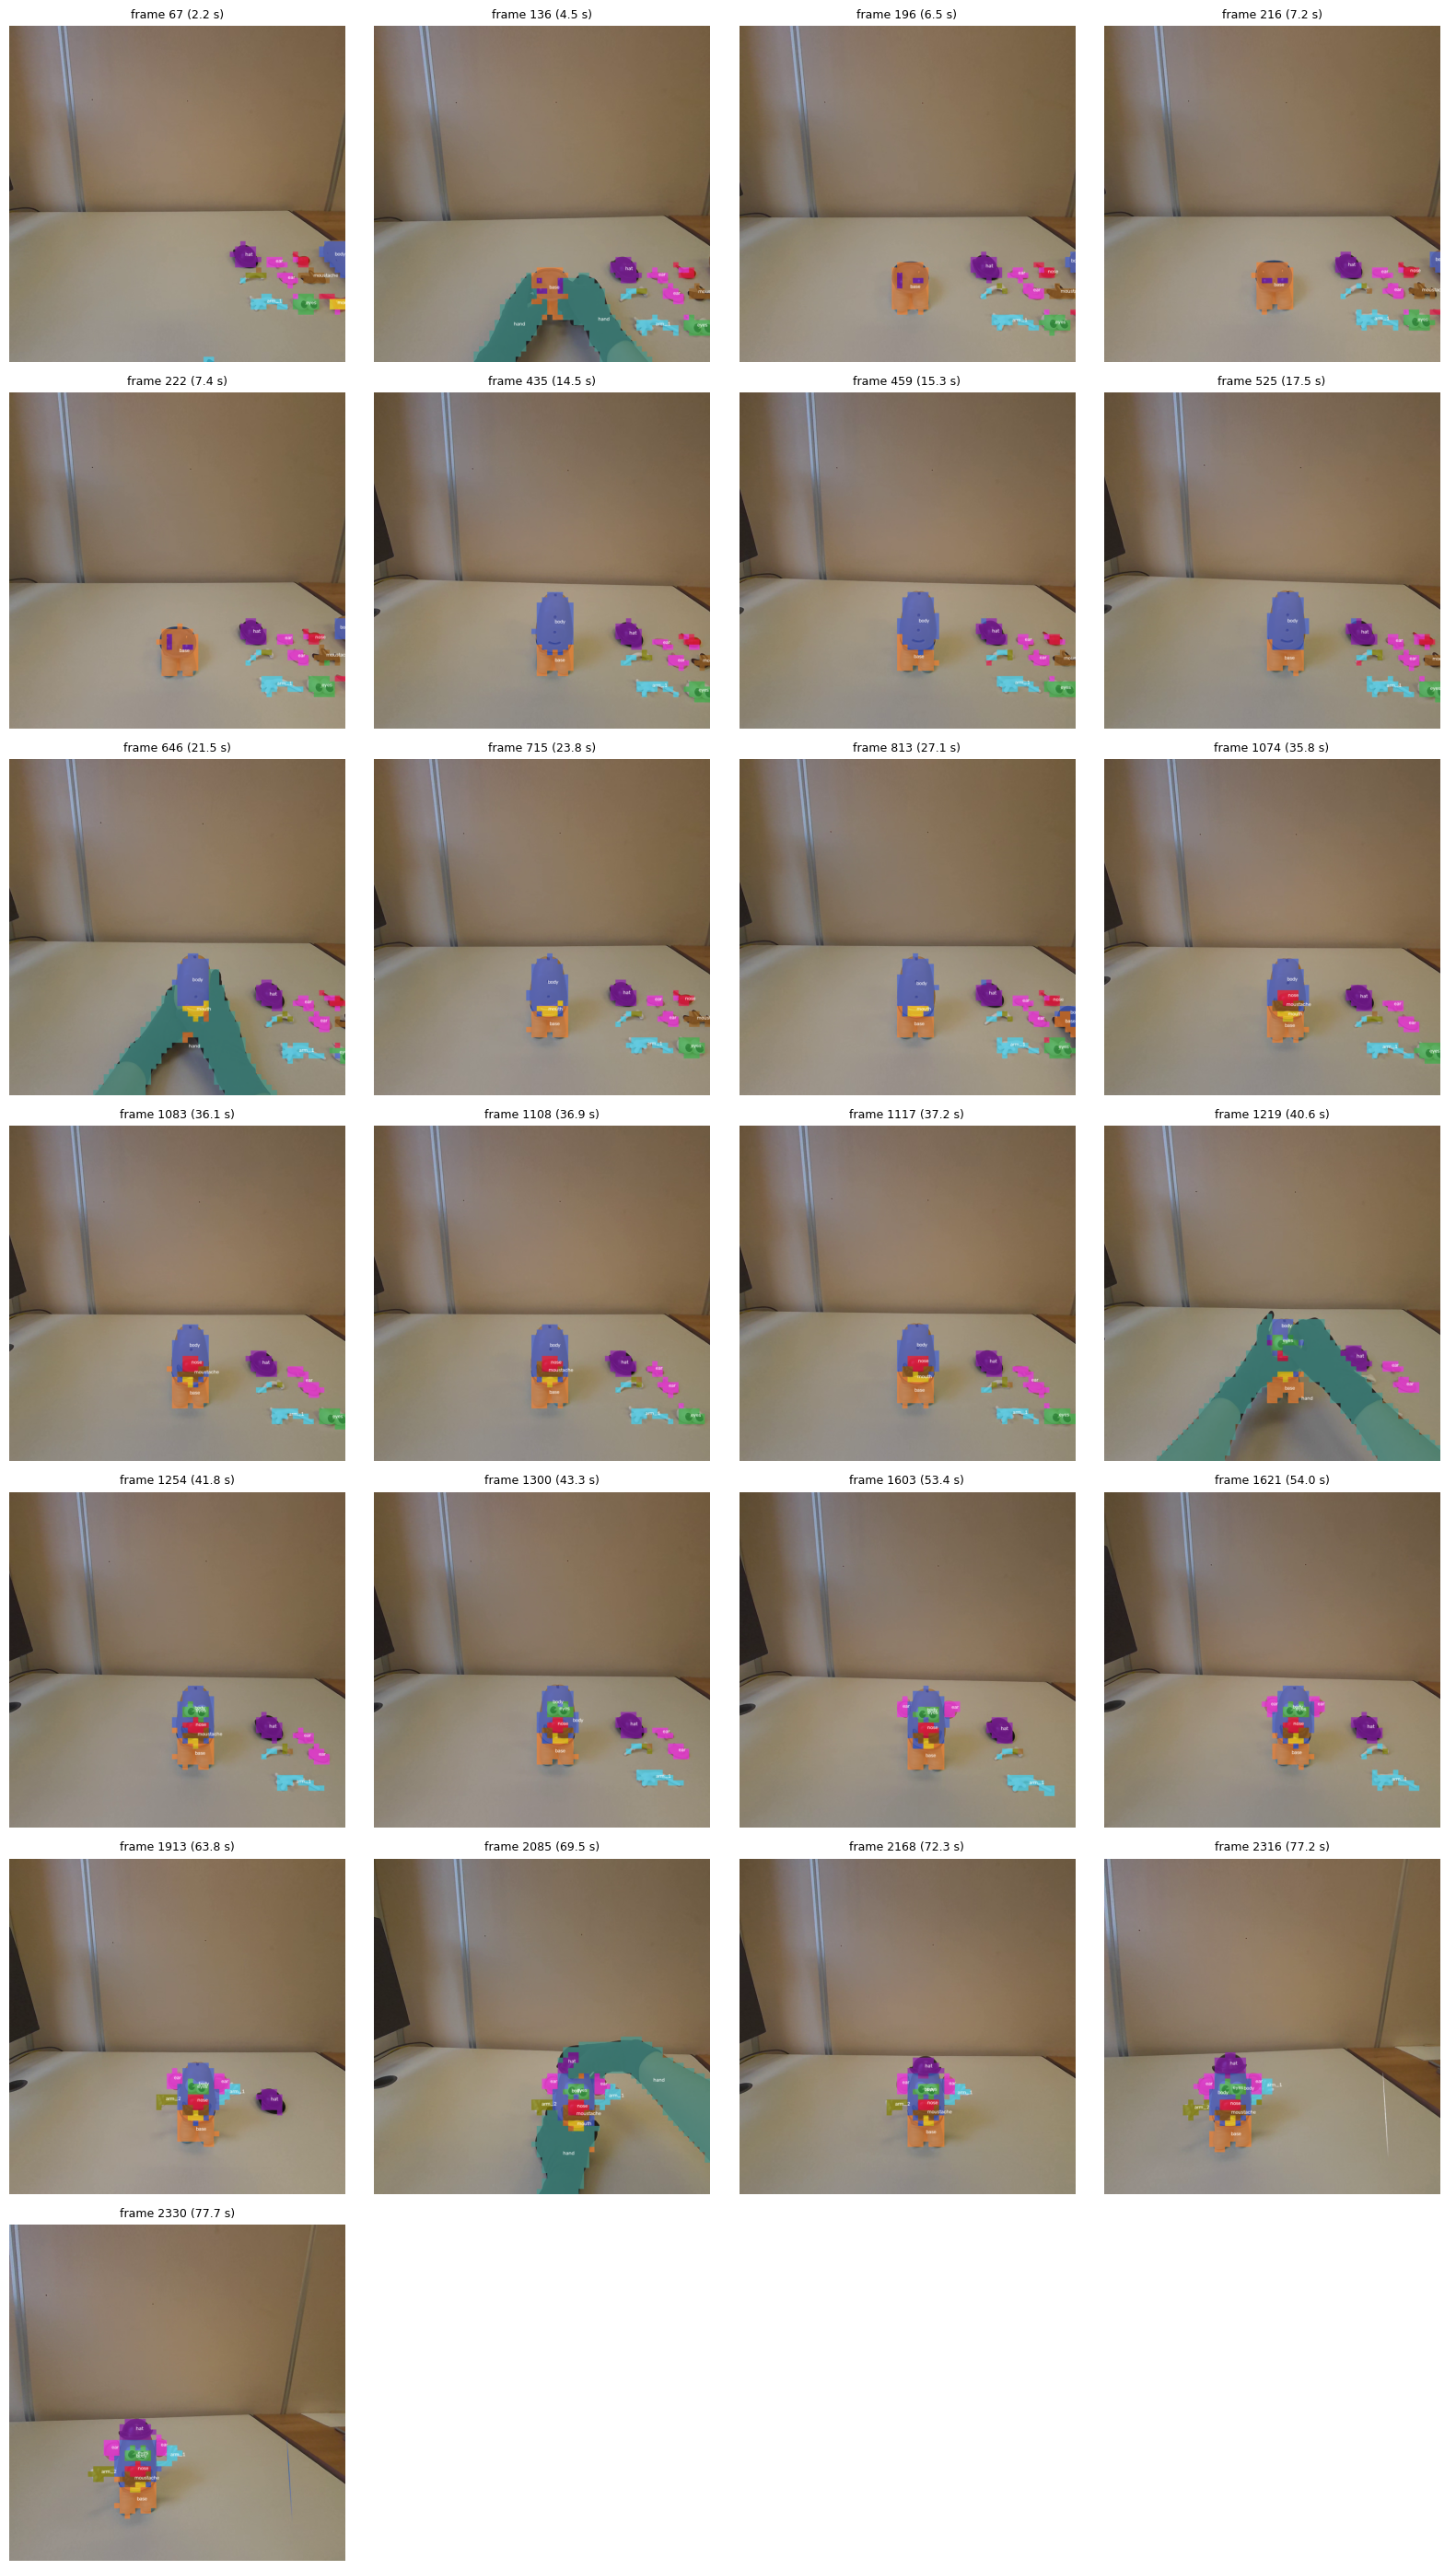

In [32]:
# 8.3 Snapshots of each C-RADIO run (pipeline 11.3); the full video is in the outputs folder
n_cols = 4
n_rows = int(np.ceil(len(snapshots) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for ax, (index, image) in zip(axes.flat, snapshots):
    ax.imshow(image)
    ax.set_title(f"frame {index} ({index / fps:.1f} s)", fontsize=9)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / f"{VIDEO_PATH.stem}_snapshots.png", dpi=120, bbox_inches="tight")
plt.show()

Observation 8.3: The snapshots follow the assembly of assembly_1: pieces loose with the base outside the frame (2.2 s), base in the hands (4.5 s) and alone at the work position (6.5-7.4 s), body on the base (14.5-17.5 s), mouth (21.5-27.1 s), nose and moustache mounted (35.8-37.2 s), eyes (41.8-43.3 s), ears (53.4-54.0 s), arms (63.8 s), hat in hand (69.5 s) and the complete figure (72.3 s), also from the second viewpoint after the head turn (77.2-77.7 s).

The errors seen in Section 7 are visible here too. The base alone shows hat patches in its cavity (6.5-7.4 s), as on assembly_2. The loose arms on the table are labelled arm_1; once mounted, the arm on the image left is labelled arm_2 and the one on the right arm_1, as in the event log. These snapshots are small and only describe what Section 7 measures.

In [33]:
# 8.4 Continuous perception: C-RADIO on every frame of the video (offline), labels and similarities saved for Phase 2
cap = cv2.VideoCapture(str(VIDEO_PATH))
fps = cap.get(cv2.CAP_PROP_FPS)
width, height = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
continuous_video = OUTPUT_DIR / f"{VIDEO_PATH.stem}_perception_continuous.mp4"
writer = cv2.VideoWriter(str(continuous_video), cv2.VideoWriter_fourcc(*"mp4v"), fps, (width, height))

continuous_labels, continuous_similarities = [], []
start = time.time()
frame_index = 0
while True:
    ok, frame_bgr = cap.read()
    if not ok:
        break
    frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    features, _ = extractor.extract(Image.fromarray(frame_rgb))
    similarities = class_similarities_gpu(features, *PROTOTYPES_GPU)
    labels = assign_labels(similarities, MARGIN)
    continuous_labels.append(labels.astype(np.uint8))
    continuous_similarities.append(similarities.astype(np.float16))

    shown = render_overlay(frame_rgb, labels, MIN_BLOB_PATCHES)
    cv2.putText(shown, f"frame {frame_index}  {frame_index / fps:.2f} s", (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1.0,
                (255, 255, 255), 2, cv2.LINE_AA)
    writer.write(cv2.cvtColor(shown, cv2.COLOR_RGB2BGR))
    frame_index += 1
    if frame_index % 300 == 0:
        print(f"{frame_index} frames, {time.time() - start:.0f} s")

cap.release()
writer.release()
CONTINUOUS_LABELS = np.stack(continuous_labels)
np.savez_compressed(
    OUTPUT_DIR / f"{VIDEO_PATH.stem}_continuous.npz",
    labels=CONTINUOUS_LABELS,
    similarities=np.stack(continuous_similarities),
    fps=fps,
    class_names=np.array(CLASS_NAMES),
    run_info=json.dumps({"git_commit": RUN_COMMIT, "prototypes_sha256": fingerprint, "margin": MARGIN,
                         "run": time.strftime("%Y-%m-%d %H:%M")}),
)
elapsed = time.time() - start
print(f"{frame_index} frames in {elapsed / 60:.1f} min ({elapsed / frame_index:.2f} s per frame). "
      f"Video: {continuous_video}. Labels: {OUTPUT_DIR / (VIDEO_PATH.stem + '_continuous.npz')}")

300 frames, 162 s
600 frames, 321 s
900 frames, 481 s
1200 frames, 643 s
1500 frames, 802 s
1800 frames, 961 s
2100 frames, 1124 s
2348 frames in 21.2 min (0.54 s per frame). Video: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\phase_1_test\assembly_1_perception_continuous.mp4. Labels: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\phase_1_test\assembly_1_continuous.npz


Observation 8.4: C-RADIO and V2 ran on all 2348 frames of assembly_1 in 21.2 min, 0.54 s per frame including the overlay and the video writing, against 0.46 s per frame for the classification alone (7.2). Continuous perception is therefore possible offline only. The labels and the similarities of every frame are saved, with the commit and the fingerprint of the prototypes, for Phase 2.

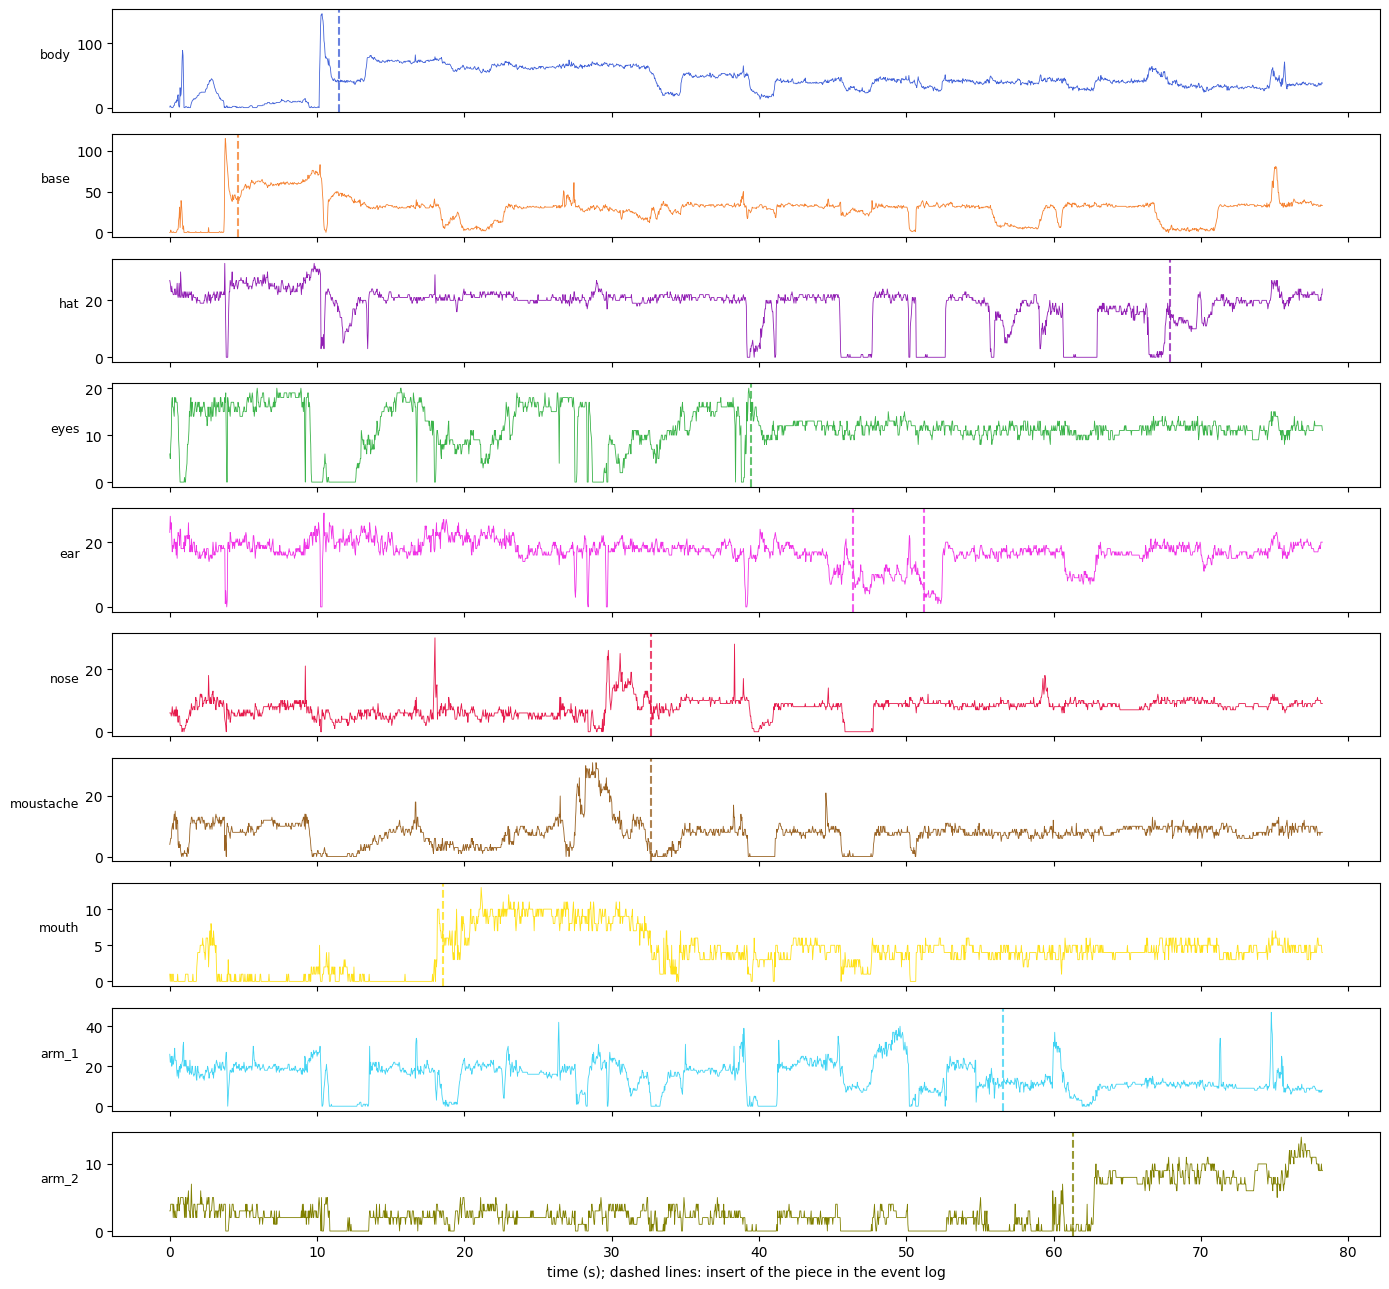

Agreement with Section 7 on the 31 test frames: mean 0.999, minimum 0.996 (assembly_1_f0018)


In [34]:
# 8.5 Patches of each piece over time (continuous perception), with the inserts of the event log;
# and agreement with Section 7 on the 31 test frames (Section 7 reads the extracted jpg frames, here frames come from the video)
times = np.arange(len(CONTINUOUS_LABELS)) / fps
pieces = [name for name in CLASS_NAMES if name in PIECE_LABELS]
fig, axes = plt.subplots(len(pieces), 1, figsize=(14, 1.3 * len(pieces)), sharex=True)
for ax, name in zip(axes, pieces):
    class_id = CLASS_NAMES.index(name)
    ax.plot(times, (CONTINUOUS_LABELS == class_id).sum(axis=(1, 2)), linewidth=0.6, color=CLASS_COLORS[name])
    for e in EVENTS:
        if e["piece"] == name:
            ax.axvline(e["insert"] / fps, color=CLASS_COLORS[name], linestyle="--", alpha=0.8)
    ax.set_ylabel(name, rotation=0, ha="right", fontsize=9)
axes[-1].set_xlabel("time (s); dashed lines: insert of the piece in the event log")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / f"{VIDEO_PATH.stem}_continuous_counts.png", dpi=120, bbox_inches="tight")
plt.show()

agreement = pd.Series({item["frame"]: float((CONTINUOUS_LABELS[GRID * item["index"]] == results[item["frame"]]["labels"]).mean())
                       for item in TEST_FRAMES}, name="share of patches with the same label")
print(f"Agreement with Section 7 on the 31 test frames: mean {agreement.mean():.3f}, minimum {agreement.min():.3f} "
      f"({agreement.idxmin()})")

Observation 8.5: The mountings appear in the counts as steps at the inserts of the event log: the base appears at 4.6 s, the body rises at about 10-11 s, the mouth at 18.5 s, the eyes settle after 39.4 s and arm_2 appears after 61 s. Once mounted, the pieces keep a stable count until the end, and in the video the complete figure is labelled correctly.

The mouth has about 10 patches from its mounting to 32.7 s and about 4 afterwards. In the video the empty slots of nose and moustache stay body: the drop comes from the moustache, mounted over the mouth, which covers part of it. The hypothesis that the empty slots are taken for mouth (pipeline, Section 10) is therefore not supported on this video.

Watching the video, four errors recur. The loose arms on the table are labelled mostly arm_1: only the closed hand of arm_2 is labelled arm_2, and arm_2 stays between 0 and 5 patches until it is mounted. The base alone shows hat patches on the dark holes on its top (7 s), as in validation. The hat is recognized on the table but labelled body when held in the hand (66.8-67.3 s). The mouth is often confused with neighbouring classes. In addition, pieces under the hands drop to zero, for instance nose, moustache and hat between 46 and 48 s.

The counts change by a few patches from one frame to the next even when the scene is still, so a state read from a single frame would flicker; Phase 2 has to decide over several frames.

On the 31 test frames the continuous labels agree with those of Section 7 on 99.9% of the patches on average, and on at least 99.6% in every frame (lowest in f0018), although here the frames are decoded from the video and there from the extracted jpg files.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 8:

Pipeline (phase_1_perception.ipynb), Section 11: the video pipeline with motion gating, its provisional parameters and its output on assembly_2.

Cawley and Talbot 2010, Sect. 5: a performance estimate on data used to make choices is optimistically biased; the test of Phase 2 is therefore a recording not used to design it.

Cells 8.4 and 8.5: continuous perception, C-RADIO on every frame offline; not possible in real time at the cost of Section 7.2 (0.46 s per frame against 33 ms between frames).

------------------------------------------------------------------------------------------------------------------------------------------

## Section 9 - Comparison with validation and conclusions

This section closes the test. Cell 9.1 reads the predictions saved by the single run (Section 7.2) and gives the values of each frame, needed for the two hypotheses of Section 5 that the totals cannot check: the arm just picked (f0055 and f0060) and the small pieces of f0073. No prediction is run.

The comparison with validation and the check of every hypothesis of Section 5 follow, then the conclusions of Phase 1.

In [35]:
# 9.1 Values of each frame, from the predictions saved by the single run (Section 7.2); no prediction is run
saved_run = np.load(OUTPUT_DIR / "predictions.npz")
saved_frames = [str(frame) for frame in saved_run["frames"]]
saved_confusions = list(saved_run["confusions"])
assert saved_frames == [item["frame"] for item in TEST_FRAMES], "The saved run does not match the test frames of Section 2.6"
print("Saved run:", json.loads(str(saved_run["run_info"])))

piece_ids = [CLASS_NAMES.index(name) for name in CLASS_NAMES if name in PIECE_LABELS]
no_exclusion = [set() for _ in saved_frames]
rows = []
for k, item in enumerate(TEST_FRAMES):
    iou = frame_iou(saved_confusions, no_exclusion, [k])
    rows.append({"frame": item["frame"], "moment": item["moment"], "piece": item["piece"] or "-",
                 "mIoU (pieces in the frame)": float(np.nanmean(iou[piece_ids])),
                 **{CLASS_NAMES[i]: iou[i] for i in piece_ids}})
per_frame = pd.DataFrame(rows).set_index("frame")
pd.set_option("display.max_columns", None)
display(per_frame.round(2))

print("Where the annotated patches of the arms go in the two pick frames of the arms:")
for name in ["assembly_1_f0055", "assembly_1_f0060"]:
    confusion = saved_confusions[saved_frames.index(name)]
    for arm in ["arm_1", "arm_2"]:
        row = confusion[CLASS_NAMES.index(arm)]
        if row.sum():
            print(f"  {name}, {arm} ({int(row.sum())} patches): "
                  + ", ".join(f"{CLASS_NAMES[j]} {int(v)}" for j, v in enumerate(row) if v))

Saved run: {'git_commit': '6ab690f', 'prototypes_sha256': 'ab0f13579f17', 'margin': 0.0, 'min_label_coverage': 0.5, 'run': '2026-10-25 10:43'}


,moment,piece,mIoU (pieces in the frame),body,base,hat,eyes,ear,nose,moustache,mouth,arm_1,arm_2
frame,,,,,,,,,,,,,
assembly_1_f0002,table,-,0.83,1.00,NaN,1.00,1.00,1.00,0.60,0.78,0.67,0.82,0.60
assembly_1_f0004,pick,base,0.77,NaN,0.95,0.78,1.00,1.00,0.86,1.00,0.00,1.00,0.33
assembly_1_f0005,mount,base,0.84,NaN,0.89,0.83,1.00,0.92,0.80,1.00,NaN,0.81,0.50
assembly_1_f0008,table,-,0.78,1.00,0.94,0.86,1.00,0.93,0.71,1.00,0.00,0.83,0.50
assembly_1_f0011,pick,body,0.52,0.74,0.92,1.00,0.00,0.78,0.75,NaN,0.00,NaN,0.00
assembly_1_f0012,mount,body,0.53,0.77,0.90,0.83,0.00,0.88,0.33,NaN,0.00,NaN,NaN
assembly_1_f0016,table,-,0.87,0.99,0.96,1.00,1.00,1.00,1.00,0.86,NaN,0.81,0.20
assembly_1_f0018,pick,mouth,0.58,0.92,0.82,0.67,NaN,0.86,0.15,0.86,0.11,0.57,0.25
assembly_1_f0019,mount,mouth,0.68,0.92,1.00,1.00,0.73,0.78,0.60,0.50,0.75,0.00,0.50


Where the annotated patches of the arms go in the two pick frames of the arms:
  assembly_1_f0055, arm_1 (6 patches): arm_1 6
  assembly_1_f0055, arm_2 (5 patches): background 1, arm_2 4
  assembly_1_f0060, arm_1 (8 patches): arm_1 8
  assembly_1_f0060, arm_2 (16 patches): arm_1 16


Observation 9.1: The cell reads the saved run (commit 6ab690f, 10:43) in the same kernel; no prediction is run.

In f0055 the arm_1 just picked is found: its 6 patches are all arm_1. In f0060 the arm_2 just picked is not missed but taken for the other arm: its 16 patches are all labelled arm_1. In f0073 the figure seen from farther away has the highest mIoU of the 31 frames, 0.92, and every piece has an IoU of at least 0.78.

The lowest frames are the pick and the mounting of the body, f0011 (0.52) and f0012 (0.53), and the pick of the mouth, f0018 (0.58). In a single frame an IoU of 0 has two opposite meanings: a piece present and not found, or a piece absent and predicted. The mouth of f0011 and f0012, for instance, is outside the frame and not annotated, so its 0 there is a false positive.

9.2 Comparison with validation and check of the hypotheses of Section 5.

The mIoU over the 10 pieces is 0.765 on the test frames (0.719-0.796) against 0.779 in validation. The test value is lower, as expected, but only by 0.014, and the validation value lies inside the test interval. By moment the order changes: the table (0.835) and the mounting (0.782) are higher than in validation, the pick (0.706) lower. The first hypothesis holds only for the total and for the pick.

arm_2 is the weakest piece (0.416), and 43.1% of its patches are labelled arm_1: this hypothesis holds. The gap between the mIoU with the arms merged and the mIoU over the 10 pieces is 0.055, against 0.057 in validation, so it is practically the same, not larger: this hypothesis holds only in substance.

16.1% of the mouth patches are labelled nose: this hypothesis holds.

The arm just picked is not missed (9.1). arm_1 in f0055 is found entirely, and arm_2 in f0060 is found but taken entirely for arm_1. The hypothesis does not hold as written: the error is the identity of the arm, not its detection.

The small pieces of f0073 are not lost (9.1): this hypothesis does not hold.

The continuous video adds one correction (Section 8.5). The empty slots of nose and moustache stay body, and the mouth shrinks when the moustache covers it, so the hypothesis of the pipeline that the empty slots are taken for mouth is not supported.

9.3 Conclusions of Phase 1.

Perception without training recognizes the ten pieces from ten annotated frames. On a recording never used for any choice it reaches a mIoU over the 10 pieces of 0.765 (95% interval 0.719-0.796), close to the 0.779 of validation, so the validation estimate was only slightly optimistic for a new recording of the same procedure. Base, hat, ear and body have an IoU between 0.86 and 0.91. Over the whole video the mounted pieces keep their class, and the complete figure is labelled correctly (Section 8).

The limits are those known from the studies, now measured on the test. The two arms are told apart only once mounted: loose, just picked or being mounted (f0060, f0062), arm_2 is labelled arm_1, except for its closed hand. The mouth is partly taken for nose. The pick is the weakest moment (0.706). The hat is taken for body when held, and appears in the holes of the base when the base is alone. Pieces under the hands disappear, and labels flicker from one frame to the next.

These limits define what Phase 2 has to provide on top of perception. A state must be decided over several frames, not one. The identity of a piece must be kept over time, so that an arm recognized once keeps its identity while it is moved. Whether a piece is mounted must come from its position relative to the body, not from its class alone. Pieces may appear already in hand, picked outside the frame. And the contact of a piece with the body and its insertion are two different moments (Section 4, arm_1 at f0057 and f0058).

The test has limits of its own. It is one recording, with the same operator, scene and order of pieces as validation, so the interval describes the variation over frames of this recording, not between recordings. Objects never seen are not tested here.

assembly_1 now becomes development material for Phase 2, like assembly_2. Phase 2 will be tested on new recordings with assembly errors, made with a phone mounted to simulate the headset, in a scene outside the laboratory.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 9:

Section 5 of this notebook: the hypotheses written before the run.

Cawley and Talbot 2010, Sect. 5: a performance estimate on data used for selection is optimistically biased.

Pipeline (phase_1_perception.ipynb), Section 10: the known limits on validation, among them the hypothesis on the empty slots.

------------------------------------------------------------------------------------------------------------------------------------------